# Análise Exploratória - ESA Anomaly Dataset (Mission2)

Este notebook faz parte de uma Iniciação Científica que estuda como avaliar a **confiabilidade de alertas em telemetria espacial**.

## Contexto

Satélites geram continuamente séries temporais chamadas de **telemetria** — medidas de temperatura, tensão, corrente e outros parâmetros dos seus subsistemas. Sistemas de monitoramento observam esses dados e emitem **alertas** quando detectam  comportamentos fora do padrão.

O problema central é que **um alerta não significa necessariamente uma falha real**.  O mesmo comportamento atípico pode ser:

- 🔴 Uma **anomalia real** — algo efetivamente errado no satélite
- 🟡 Um **evento nominal raro** — uma operação planejada, incomum mas esperada  (ex: uma manobra, uma calibração)
- ⚪ **Ruído ou problema de qualidade dos dados**

Esta análise exploratória vai nos ajudar a **entender a estrutura dos dados disponíveis** antes de construir qualquer detector ou avaliador de alertas. Ela é o equivalente, para a **Mission2**, da análise já feita para a Mission1.

In [1]:
# ==============================================================================
# Imports principais e configurações globais
# ==============================================================================
import pickle
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd

# Diretório dos dados da Missão 2
DATA_DIR = Path("../../data/ESA/ESA-Mission2")

# Subconjunto leve (lightweight) recomendado pelo ESA-ADB para a Mission2:
# canais 18 a 28, todos do Subsistema 1.
IDS_CANAIS_EDA = list(range(18, 29))
CANAIS_EDA = [f"channel_{i}" for i in IDS_CANAIS_EDA]
ROTULO_CANAIS = f"{IDS_CANAIS_EDA[0]}–{IDS_CANAIS_EDA[-1]}"

# Paleta de cores padronizada e semântica para todo o notebook
# (a mesma da Mission1, para que os gráficos sejam comparáveis):
# - Vermelho: Anomalias (falhas reais)
# - Amarelo/Laranja: Eventos Raros (operações planejadas, esperadas)
# - Azul: Communication Gap (pausas na transmissão)
# - Cinza: Leituras nominais ou sem anotação
CORES_CATEGORIAS = {
    "Anomaly": "#d9534f",
    "Rare Event": "#f0ad4e",
    "Communication Gap": "#5bc0de",
    "Sem anotação conhecida": "#6c757d",
    "Mais de uma categoria": "#6f42c1",
}


def load_zip_pickle(path: Path) -> pd.DataFrame:
    """Carrega um DataFrame serializado (pickle) de dentro de um arquivo ZIP."""
    with zipfile.ZipFile(path) as z:
        nome_arquivo = z.namelist()[0]
        return pickle.loads(z.read(nome_arquivo))


def indice_ns(indice: pd.DatetimeIndex) -> np.ndarray:
    """Timestamps como inteiros em nanossegundos (independe da resolução do pandas)."""
    try:
        return indice.as_unit("ns").asi8
    except AttributeError:  # pandas < 2.0
        return indice.asi8


def intervalos_em_segundos(indice: pd.DatetimeIndex) -> np.ndarray:
    """Diferença, em segundos, entre leituras consecutivas."""
    return np.diff(indice_ns(indice)).astype(np.float64) / 1e9


def para_naive(serie_datas) -> pd.Series:
    """Converte datas (UTC-aware ou texto) para datetime sem fuso, em UTC."""
    return pd.to_datetime(serie_datas, utc=True).dt.tz_localize(None)

## O que vamos fazer aqui

Este notebook segue **a mesma progressão da Mission1**, para que os resultados possam ser comparados:

1. **Carregar e inspecionar os metadados** (CSVs) — entender o que existe antes de abrir os arquivos grandes
2. **Carregar as séries temporais** dos canais 18 - 28 — ver como os dados reais se parecem
3. **Visualizar os canais** — identificar padrões, anomalias e eventos nominais raros visualmente
4. **Carregar e visualizar telecomandos** — entender quando e com que frequência comandos foram enviados
5. **Explorar a possibilidade de combinação** — verificar se faz sentido cruzar séries de
   telemetria com o histórico de telecomandos (join temporal)

## Escopo desta etapa: Mission2

Esta é a análise exploratória da **Mission2** do ESA-ADB, equivalente à já realizada para a Mission1. Os resultados da Mission1 servem de **referência de comparação**, mas nenhuma conclusão é transferida automaticamente de uma missão para a outra.

### Recorte atual

- **Telemetria:** canais 18–28 (**subconjunto leve**, ou *lightweight subset*, do ESA-ADB), todos do **Subsistema 1**. É um conjunto de 11 canais selecionado no benchmark por permitir a análise em isolamento e por conter os principais desafios da missão (como eventos nominais raros e manobras), sendo a escolha ideal para a fase exploratória e para prototipagem. Os canais efetivamente carregados serão conferidos na seção de carregamento.
- **Conjunto completo (*full set*):** 100 canais, em 5 subsistemas e 29 grupos, dos quais 47 são canais-alvo (*target channels*, monitorados ativamente para detecção de anomalias) e 53 são canais de apoio (*non-target*, com flags de status, contadores e metadados que fornecem contexto). Esses números vêm do artigo do benchmark e serão **confirmados** com `channels.csv`.
- **Eventos:** rótulos associados aos canais 18–28, cruzados com `anomaly_types.csv`. As contagens de eventos desta análise serão de **IDs únicos presentes no recorte**, não do total da Mission2.
- **Telecomandos:** catálogo da Mission2 e históricos disponíveis em `telecommands/`, usados para caracterização e análise de proximidade temporal. Uma associação temporal não demonstra causalidade.

### O que esta EDA deve produzir

Vamos caracterizar os eventos, os canais, a amostragem, a qualidade dos dados e o histórico de telecomandos. Também podemos construir uma **baseline exploratória** para visualizar como regras simples se comportam; ela não substitui a avaliação formal do detector, que deverá respeitar os períodos de treino, validação e teste e as métricas apropriadas do benchmark.

As conclusões desta etapa ficam limitadas à Mission2 e aos canais selecionados. Não serão generalizadas para todos os canais da missão nem para a Mission1.

> ⚙️ **Sobre este notebook:** o código foi escrito para **descobrir** o que existe nos dados (canais disponíveis, período, cadência de amostragem, telecomandos mais frequentes, eventos de exemplo) em vez de assumir valores da Mission1. As células de texto marcadas com _"Preencher após executar"_ são o lugar para registrar os números e conclusões reais da Mission2.

## O dataset: ESA-ADB Mission2

Usamos o **ESA Anomaly Detection Benchmark (ESA-ADB)**, um benchmark público  publicado pela Agência Espacial Europeia (ESA) em parceria com a KP Labs.

> 📎 [Artigo original](https://arxiv.org/abs/2406.17826)

> [Repositório oficial](https://github.com/kplabs-pl/ESA-ADB)

> [Zenodo (dados)](https://doi.org/10.5281/zenodo.12528696)

### ⚠️ Importante: os dados são anonimizados

Os nomes reais dos canais, subsistemas e telecomandos **não são divulgados**.  Por isso, você verá identificadores genéricos como `channel_18`, `subsystem_1`  e `telecommand_10`. Isso é intencional — protege informações proprietárias da missão.

### O que está disponível neste subconjunto

| Arquivo | O que contém |
|---|---|
| `channels.csv` | Catálogo dos canais da missão: subsistema, unidade física, grupo, flag de alvo |
| `labels.csv` | Eventos rotulados por canal (início, fim, tipo de evento) |
| `anomaly_types.csv` | Tipos de eventos: Anomalia vs. Evento Nominal Raro (e lacunas de comunicação) |
| `telecommands.csv` | Catálogo dos tipos de telecomandos com prioridade |
| `events.csv` | Tabela de eventos da missão (existe na pasta da Mission2; será inspecionada, ver nota abaixo) |
| `channels/channel_{18..28}.zip` | Séries temporais dos canais 18 a 28 |
| `telecommands/telecommand_*.zip` | Histórico de quando cada comando foi executado |

> 📝 O arquivo `events.csv` não foi usado na análise da Mission1. Aqui ele é apenas inspecionado (formato e colunas) para decidir, depois, se agrega algo além de `labels.csv` + `anomaly_types.csv`.

### Estrutura dos arquivos de série temporal

Os arquivos `.zip` de canais e telecomandos contêm **DataFrames pickled**  (serializados em formato Python). Cada um tem:

- **Índice:** `datetime` — o timestamp da medição ou execução do comando
- **Coluna:** o valor medido (canal) ou uma flag `1` indicando execução (telecomando)

Os **canais do subconjunto leve** pertencem ao mesmo subsistema, o que significa que monitoram aspectos relacionados do satélite.

Os **telecomandos** registram os comandos enviados ao satélite ao longo dos anos. Cada arquivo corresponde a um tipo de comando e armazena todos os momentos em que ele foi executado. Alguns comandos são raros (poucas execuções) e outros são frequentes (centenas de milhares).

In [2]:
channels_meta = pd.read_csv(DATA_DIR / "channels.csv")
labels = pd.read_csv(DATA_DIR / "labels.csv")
anomaly_types = pd.read_csv(DATA_DIR / "anomaly_types.csv")
tc_meta = pd.read_csv(DATA_DIR / "telecommands.csv")
events_csv = pd.read_csv(DATA_DIR / "events.csv")   # apenas inspeção (não usado na Mission1)

# Quais canais do recorte realmente têm arquivo .zip nesta máquina?
canais_disponiveis = [
    nome for nome in CANAIS_EDA if (DATA_DIR / "channels" / f"{nome}.zip").exists()
]
canais_faltando = [nome for nome in CANAIS_EDA if nome not in canais_disponiveis]
print(f"Canais do recorte com arquivo disponível: {len(canais_disponiveis)} de {len(CANAIS_EDA)}")
if canais_faltando:
    print("⚠️ Sem arquivo .zip:", canais_faltando)
print("Telecomandos (.zip) na pasta:", len(list((DATA_DIR / "telecommands").glob("telecommand_*.zip"))))

Canais do recorte com arquivo disponível: 11 de 11
Telecomandos (.zip) na pasta: 123


### 📡 Tabela 1: `channels.csv` — "Quais sensores existem no satélite?"

Cada linha representa um **canal de telemetria** — uma série temporal coletada  continuamente pelo satélite.

> Exemplo: Imagine que o satélite é como um avião. Dentro dele existem dezenas de sensores  medindo coisas o tempo todo: temperatura do motor, nível de combustível, pressão  da cabine, etc. No mundo dos satélites, cada um desses sensores é chamado de **canal**. Esta tabela é basicamente o **manual de bordo** — ela lista todos os canais  existentes e diz o que cada um mede.

| Coluna | O que significa |
|---|---|
| `Channel` | Nome identificador do canal (ex.: `channel_18`). Anonimizado. |
| `Subsystem` | Subsistema do satélite ao qual o canal pertence. Um subsistema agrupa componentes relacionados (ex: energia, atitude, comunicação). Também anonimizado. |
| `Physical Unit` | Tipo de grandeza física medida (ex: temperatura, tensão, corrente). Anonimizado. |
| `Group` | Agrupamento temático dos canais — canais do mesmo grupo tendem a medir aspectos relacionados. |
| `Target` | `YES` indica que este canal é **alvo da detecção de anomalias**. `NO` significa que o canal existe apenas como contexto e não é avaliado diretamente. |

> 💡 Conferir na saída abaixo: quantos canais existem no total, quantos são `Target=YES`, e se os canais 18–28 pertencem ao mesmo subsistema e grupo ou se há mais de um grupo no recorte.

In [3]:
print("=== channels_meta ===")
display(channels_meta.head())

print(f"Canais no catálogo: {len(channels_meta)} | "
      f"Subsistemas: {channels_meta['Subsystem'].nunique()} | "
      f"Grupos: {channels_meta['Group'].nunique()}")
print(channels_meta['Target'].value_counts())
print('')

print(f"=== channels_meta (canais {ROTULO_CANAIS}) ===")
meta_recorte = channels_meta[channels_meta["Channel"].isin(CANAIS_EDA)]
display(meta_recorte)
print("Subsistemas no recorte:", meta_recorte["Subsystem"].unique().tolist())
print("Grupos no recorte:", meta_recorte["Group"].unique().tolist())
print("Target no recorte:", meta_recorte["Target"].value_counts().to_dict())

=== channels_meta ===


,Channel,Subsystem,Physical Unit,Group,Target
0,channel_1,subsystem_1,physical_unit_7,7,NO
1,channel_2,subsystem_1,physical_unit_7,7,NO
2,channel_3,subsystem_1,physical_unit_7,7,NO
3,channel_4,subsystem_4,physical_unit_8,21,NO
4,channel_5,subsystem_1,physical_unit_8,19,NO


Canais no catálogo: 100 | Subsistemas: 5 | Grupos: 29
Target
NO     53
YES    47
Name: count, dtype: int64

=== channels_meta (canais 18–28) ===


,Channel,Subsystem,Physical Unit,Group,Target
17,channel_18,subsystem_1,NaN,5,YES
18,channel_19,subsystem_1,NaN,5,YES
19,channel_20,subsystem_1,NaN,5,YES
20,channel_21,subsystem_1,physical_unit_9,2,YES
21,channel_22,subsystem_1,physical_unit_9,2,YES
22,channel_23,subsystem_1,physical_unit_9,2,YES
23,channel_24,subsystem_1,physical_unit_9,2,YES
24,channel_25,subsystem_1,NaN,1,YES
25,channel_26,subsystem_1,NaN,1,YES
26,channel_27,subsystem_1,NaN,1,YES


Subsistemas no recorte: ['subsystem_1']
Grupos no recorte: [5, 2, 1]
Target no recorte: {'YES': 11}


### 🏷️ Tabela 2: `labels.csv` — "O que realmente aconteceu, e quando?"

Quando engenheiros da ESA analisaram os dados históricos do satélite, eles identificaram eventos importantes e anotaram: *"entre essa data e essa data, aconteceu alguma coisa nesse canal"*.

Essa tabela é o resultado dessas anotações — o nosso **gabarito oficial**. Ela nos diz o que de fato ocorreu, o que é essencial para avaliar se um detector automático teria acertado ou errado.

| Coluna | Significado simples |
|---|---|
| `ID` | O "nome" do evento. Se o mesmo `ID` aparece em várias linhas, significa que aquele evento afetou vários canais ao mesmo tempo — não foi só um sensor que reagiu, foram vários juntos. |
| `Channel` | Qual sensor registrou esse evento. |
| `StartTime` | Quando o evento começou. |
| `EndTime` | Quando o evento terminou. |

> ⚠️ **Repare numa coisa:** o `ID` aqui identifica a *ocorrência* — ou seja,  "aconteceu uma vez". Ele **não diz** se foi uma coisa grave ou inofensiva. Para saber isso, precisamos cruzar com a próxima tabela.

> Na Mission1, uma linha tinha texto (`"Resultado"`) no lugar da data em `StartTime`. Na Mission2 essa verificação será refeita na seção de auditoria dos rótulos; **não se assume** que o mesmo problema exista (ou não) aqui.

In [4]:
print("=== labels ===")
display(labels.head())

print(f"=== labels (canais {ROTULO_CANAIS}) ===")
display(labels[labels["Channel"].isin(CANAIS_EDA)])

=== labels ===


,ID,Channel,StartTime,EndTime
0,id_1,channel_9,2000-04-22T18:00:50.559Z,2000-04-22T20:57:32.577Z
1,id_1,channel_10,2000-04-22T18:00:50.559Z,2000-04-22T18:08:02.559Z
2,id_1,channel_11,2000-04-22T18:00:50.559Z,2000-04-22T19:50:38.571Z
3,id_1,channel_12,2000-04-22T18:03:50.559Z,2000-04-22T20:39:14.574Z
4,id_1,channel_13,2000-04-22T18:00:50.559Z,2000-04-22T20:50:02.577Z


=== labels (canais 18–28) ===


,ID,Channel,StartTime,EndTime
9,id_1,channel_18,2000-04-22T18:00:14.559Z,2000-04-22T21:04:44.577Z
10,id_1,channel_19,2000-04-22T18:00:14.559Z,2000-04-22T18:02:38.559Z
11,id_1,channel_19,2000-04-22T18:03:14.559Z,2000-04-22T18:06:50.559Z
12,id_1,channel_19,2000-04-22T18:07:26.559Z,2000-04-22T19:08:20.565Z
13,id_1,channel_20,2000-04-22T18:00:14.559Z,2000-04-22T20:18:14.574Z
...,...,...,...,...
11150,id_642,channel_24,2002-05-11T08:12:21.462Z,2002-05-11T08:27:57.462Z
11151,id_642,channel_24,2002-05-11T13:31:13.245Z,2002-05-11T13:47:27.495Z
11152,id_642,channel_24,2002-05-11T18:46:13.278Z,2002-05-11T19:00:57.528Z
11153,id_642,channel_24,2002-05-12T00:01:13.311Z,2002-05-12T00:15:57.561Z


### 🔍 Tabela 3: `anomaly_types.csv` — "Esse evento foi um problema ou era esperado?"

Nem todo comportamento fora do normal é uma falha. Imagine um avião realizando  uma manobra de pouso: os sensores vão registrar coisas bem diferentes do voo normal — mas isso é *esperado*, não é um problema.

Esta tabela classifica cada tipo de evento:

| Coluna | Significado simples |
|---|---|
| `ID` | Liga com o `ID` da tabela anterior — é assim que descobrimos *o que era* aquele evento. |
| `Class` / `Subclass` | Uma classificação técnica mais detalhada do tipo de evento. Os nomes reais foram anonimizados, mas eventos da mesma classe têm características em comum. |
| `Category` | **A coluna mais importante de todas.** Valores esperados: |
| | 🔴 **`Anomaly`** → algo deu errado. É o tipo de evento que um sistema de monitoramento *precisa* detectar. |
| | 🟡 **`Rare Event`** → aconteceu algo incomum, mas que era *esperado* — uma manobra, uma calibração, uma mudança de modo de operação. Não é uma falha, mas parece estranho nos dados. |
| | 🔵 **`Communication Gap`** → período sem dados (se existir nesta missão). |
| `Locality` | Se o evento foi visível em um trecho pequeno (`Local`) ou em um período longo (`Global`) da série de dados. |
| `Length` | Se o evento é pontual (`Point`) ou tem começo e fim definidos (`Subsequence`). |

> 💡 **Por que isso importa para a pesquisa?**
> Um detector automático simples vai gerar um alerta tanto para uma `Anomaly` quanto para um `Rare Event` — os dois parecem "estranhos" nos dados. O nosso objetivo é entender se é possível usar informações de contexto (como comandos  enviados ao satélite) para ajudar a distinguir um do outro, sem precisar de um especialista humano.

In [5]:
print("=== anomaly_types ===")
display(anomaly_types.head())
print("Colunas:", anomaly_types.columns.tolist())
print(anomaly_types["Category"].value_counts(dropna=False))
for coluna in ["Dimensionality", "Locality", "Length"]:
    if coluna in anomaly_types.columns:
        print(f"\n{coluna}:", anomaly_types[coluna].value_counts(dropna=False).to_dict())

=== anomaly_types ===


,ID,Class,Subclass,Category,Dimensionality,Locality,Length
0,id_1,class_30,unknown,Rare Event,Multivariate,Global,Subsequence
1,id_2,class_8,unknown,Rare Event,Multivariate,Global,Subsequence
2,id_3,class_19,unknown,Rare Event,Multivariate,Global,Subsequence
3,id_4,class_30,unknown,Rare Event,Multivariate,Global,Subsequence
4,id_5,class_19,unknown,Rare Event,Multivariate,Global,Subsequence


Colunas: ['ID', 'Class', 'Subclass', 'Category', 'Dimensionality', 'Locality', 'Length']
Category
Rare Event    613
Anomaly        31
Name: count, dtype: int64

Dimensionality: {'Multivariate': 635, 'Univariate': 9}

Locality: {'Global': 585, 'Local': 59}

Length: {'Subsequence': 644}


### 🛰️ Tabela 4: `tc_meta` (`telecommands.csv`) — "Que comandos podem ser enviados ao satélite?"

O satélite não funciona sozinho. A equipe em terra pode enviar **comandos** para ele — instruções como "ligue esse sensor", "mude a orientação", "entre em modo de economia de energia". Esses comandos se chamam **telecomandos** (TC).

Esta tabela é os **tipos de comandos disponíveis**: lista todos os tipos de telecomandos que existem nessa missão.

| Coluna | Significado simples |
|---|---|
| `Telecommand` | O código do tipo de comando (ex: `telecommand_10`). Anonimizado, assim como os canais. |
| `Priority` | Uma indicação de quão "urgente" ou "importante" esse tipo de comando é. |

> 📌 **O que essa tabela NÃO tem:** ela não diz *quando* cada comando foi usado.

> O **histórico real de execuções** — ou seja, *"em qual data e hora o `telecommand_10` foi enviado ao satélite?"* — está nos arquivos `.zip` dentro da pasta `telecommands/`. Vamos carregar esses arquivos nas próximas células para explorar isso.

> A ideia é verificar: se um telecomando foi enviado pouco antes de um sensor registrar algo incomum, isso pode ser uma pista de que o "comportamento estranho" era na verdade uma resposta *esperada* ao comando — e não uma falha.

In [6]:
print("=== tc_meta ===")
print(f"Tipos de telecomando no catálogo: {len(tc_meta)}")
display(tc_meta.head())
display(tc_meta.tail())
print("Distribuição de Priority:")
display(tc_meta["Priority"].value_counts(dropna=False).rename_axis("Priority").to_frame("tipos"))

print("\n=== events.csv (apenas inspeção) ===")
print("Formato:", events_csv.shape)
display(events_csv.head())

=== tc_meta ===
Tipos de telecomando no catálogo: 123


,Telecommand,Priority
0,telecommand_1,3
1,telecommand_2,2
2,telecommand_3,2
3,telecommand_4,2
4,telecommand_5,2


,Telecommand,Priority
118,telecommand_119,2
119,telecommand_120,2
120,telecommand_121,2
121,telecommand_122,2
122,telecommand_123,3


Distribuição de Priority:


,tipos
Priority,
2,119
3,4



=== events.csv (apenas inspeção) ===
Formato: (604, 3)


,Event,StartTime,EndTime
0,event_1,2000-05-29T02:30:07.863Z,2000-05-29T02:41:13.866Z
1,event_2,2000-05-29T02:41:21.651Z,2000-05-29T03:25:19.869Z
2,event_3,2000-05-29T03:25:37.869Z,2000-05-29T03:26:13.869Z
3,event_4,2000-05-25T00:27:07.260Z,2000-05-25T00:40:19.266Z
4,event_5,2000-04-15T03:00:00.000Z,2000-04-16T05:30:00.000Z


## 📂 Os dados reais: séries temporais dos canais 18–28

Até agora vimos apenas as **tabelas de metadados** — informações *sobre* os dados. Agora vamos abrir os arquivos que contêm as **leituras reais dos sensores**: o que o satélite mediu ao longo de anos de operação.

### Como esses arquivos funcionam?

Cada canal tem um arquivo `.zip` próprio. Dentro de cada ZIP há um único arquivo no formato **pickle** — um formato do Python para salvar objetos diretamente, sem precisar converter para texto. O resultado, ao carregar, é um `DataFrame` do pandas com esta estrutura:

| O quê | Detalhes |
|---|---|
| **Índice** | Timestamps — data e hora de cada leitura |
| **Coluna** | O valor medido pelo sensor naquele instante (número decimal) |

> 💡 Os timestamps podem **não ser igualmente espaçados** — o satélite nem sempre mede no mesmo intervalo. Isso é importante de entender antes de fazer qualquer análise temporal. Na Mission1 a cadência mediana era de 30 s; **na Mission2 ela será medida, não assumida**.

> ⚠️ Cada arquivo pode ser grande (milhões de linhas). Por isso, para visualizar, vamos usar recortes e amostras.

> 🔎 **Canal de referência.** Várias análises detalhadas usaram apenas o `channel_41` na Mission1. Aqui, o código escolhe automaticamente um **canal de referência** entre os canais carregados (primeiro canal `Target=YES` com variação suficiente). Para forçar outro, preencha `CANAL_REF_MANUAL` na célula abaixo.

In [7]:
# Carregar todos os canais disponíveis do recorte
channels = {}
for nome in canais_disponiveis:
    channels[nome] = load_zip_pickle(DATA_DIR / "channels" / f"{nome}.zip")

# ---------------- Canal de referência ----------------
CANAL_REF_MANUAL = None   # ex.: "channel_21" para forçar um canal específico

def escolher_canal_referencia():
    alvo = set(
        channels_meta.loc[channels_meta["Target"].astype(str).str.upper() == "YES", "Channel"]
    )
    com_variacao = []
    for nome, df in channels.items():
        amostra = pd.to_numeric(df.iloc[::50, 0], errors="coerce")
        if amostra.nunique() > 10:
            com_variacao.append(nome)
    for nome in com_variacao:
        if nome in alvo:
            return nome
    return com_variacao[0] if com_variacao else next(iter(channels))

CANAL_REF = CANAL_REF_MANUAL or escolher_canal_referencia()
ch_ref = channels[CANAL_REF]
print(f"Canal de referência usado nas análises detalhadas: {CANAL_REF}\n")

print("=== Primeiras leituras ===")
display(ch_ref.head())

print("=== Últimas leituras ===")
display(ch_ref.tail())

print("=== Resumo estatístico ===")
display(ch_ref.describe())

print("\n=== Informações gerais de todos os canais ===")
for nome, df in channels.items():
    inicio = df.index.min()
    fim = df.index.max()
    duracao = fim - inicio
    print(f"{nome}: {len(df):>12,.0f} leituras | {inicio.date()} → {fim.date()} | duração: {duracao.days} dias")

/tmp/ipykernel_117076/4121070628.py:41: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  return pickle.loads(z.read(nome_arquivo))


Canal de referência usado nas análises detalhadas: channel_18

=== Primeiras leituras ===


,channel_18
datetime,
2000-01-01 00:00:16.284,0.456093
2000-01-01 00:00:34.284,0.456078
2000-01-01 00:00:52.284,0.456086
2000-01-01 00:01:10.284,0.455995
2000-01-01 00:01:26.034,0.455995


=== Últimas leituras ===


,channel_18
datetime,
2003-06-30 23:58:58.416,0.456106
2003-06-30 23:59:14.169,0.456106
2003-06-30 23:59:16.416,0.456061
2003-06-30 23:59:34.416,0.456053
2003-06-30 23:59:52.416,0.456069


=== Resumo estatístico ===


,channel_18
count,7.387262e+06
mean,4.590731e-01
std,4.058806e-02
min,0.000000e+00
25%,4.559867e-01
50%,4.560245e-01
75%,4.560631e-01
max,1.000000e+00



=== Informações gerais de todos os canais ===
channel_18:    7,387,262 leituras | 2000-01-01 → 2003-06-30 | duração: 1276 dias
channel_19:    7,387,262 leituras | 2000-01-01 → 2003-06-30 | duração: 1276 dias
channel_20:    7,387,262 leituras | 2000-01-01 → 2003-06-30 | duração: 1276 dias
channel_21:    7,387,262 leituras | 2000-01-01 → 2003-06-30 | duração: 1276 dias
channel_22:    7,387,262 leituras | 2000-01-01 → 2003-06-30 | duração: 1276 dias
channel_23:    7,387,262 leituras | 2000-01-01 → 2003-06-30 | duração: 1276 dias
channel_24:    7,387,262 leituras | 2000-01-01 → 2003-06-30 | duração: 1276 dias
channel_25:    7,387,262 leituras | 2000-01-01 → 2003-06-30 | duração: 1276 dias
channel_26:    7,387,262 leituras | 2000-01-01 → 2003-06-30 | duração: 1276 dias
channel_27:    7,387,262 leituras | 2000-01-01 → 2003-06-30 | duração: 1276 dias
channel_28:    7,387,262 leituras | 2000-01-01 → 2003-06-30 | duração: 1276 dias


In [8]:
linhas_auditoria_canais = []
for nome, df in channels.items():
    indice = df.index
    valores = pd.to_numeric(df.iloc[:, 0], errors="coerce").to_numpy(dtype=float)
    linhas_auditoria_canais.append({
        "canal": nome,
        "n_linhas": len(df),
        "indice_datetime": isinstance(indice, pd.DatetimeIndex),
        "ordenado": indice.is_monotonic_increasing,
        "duplicados": int(indice.duplicated().sum()),
        "nulos_ou_nao_numericos": int(np.isnan(valores).sum()),
        "infinitos": int(np.isinf(valores).sum()),
        "inicio": indice.min(),
        "fim": indice.max(),
    })
auditoria_canais = pd.DataFrame(linhas_auditoria_canais).set_index("canal")
display(auditoria_canais)

# Na Mission1 qualquer problema interrompia a execução. Como a Mission2 ainda não foi
# explorada, os problemas são apenas REPORTADOS aqui; decida o tratamento depois de ver.
avisos = []
if not auditoria_canais["indice_datetime"].all():
    avisos.append("Há índices que não são DatetimeIndex: revise o carregamento.")
if not auditoria_canais["ordenado"].all():
    avisos.append("Há séries fora de ordem. Investigue antes de ordenar.")
if (auditoria_canais["duplicados"] > 0).any():
    avisos.append("Há timestamps repetidos. Investigue antes de agregar.")
if (auditoria_canais[["nulos_ou_nao_numericos", "infinitos"]] > 0).any().any():
    avisos.append("Há valores inválidos (nulos, não numéricos ou infinitos).")
print("Avisos da auditoria:", avisos if avisos else "nenhum problema encontrado.")

linhas_amostragem_basica = []
for nome, df in channels.items():
    intervalos_s = intervalos_em_segundos(df.index)
    positivos = intervalos_s[intervalos_s > 0]
    linhas_amostragem_basica.append({
        "canal": nome,
        "mediana_s": float(np.median(positivos)),
        "p95_s": float(np.percentile(positivos, 95)),
        "maximo_s": float(np.max(intervalos_s)),
        "intervalos_nao_positivos": int((intervalos_s <= 0).sum()),
    })
resumo_amostragem = pd.DataFrame(linhas_amostragem_basica).set_index("canal")
display(resumo_amostragem)

# Cadência mediana do canal de referência: base dos limiares de "pausa" usados adiante
MEDIANA_AMOSTRAGEM_S = float(resumo_amostragem.loc[CANAL_REF, "mediana_s"])
print(f"Cadência mediana do canal de referência: {MEDIANA_AMOSTRAGEM_S:g} s")

# Os canais compartilham exatamente os mesmos timestamps?
mesmos_timestamps = {nome: df.index.equals(ch_ref.index) for nome, df in channels.items()}
print("Mesmos timestamps do canal de referência:", mesmos_timestamps)

,n_linhas,indice_datetime,ordenado,duplicados,nulos_ou_nao_numericos,infinitos,inicio,fim
canal,,,,,,,,
channel_18,7387262,True,True,0,0,0,2000-01-01 00:00:16.284,2003-06-30 23:59:52.416
channel_19,7387262,True,True,0,0,0,2000-01-01 00:00:16.284,2003-06-30 23:59:52.416
channel_20,7387262,True,True,0,0,0,2000-01-01 00:00:16.284,2003-06-30 23:59:52.416
channel_21,7387262,True,True,0,0,0,2000-01-01 00:00:16.284,2003-06-30 23:59:52.416
channel_22,7387262,True,True,0,0,0,2000-01-01 00:00:16.284,2003-06-30 23:59:52.416
channel_23,7387262,True,True,0,0,0,2000-01-01 00:00:16.284,2003-06-30 23:59:52.416
channel_24,7387262,True,True,0,0,0,2000-01-01 00:00:16.284,2003-06-30 23:59:52.416
channel_25,7387262,True,True,0,0,0,2000-01-01 00:00:16.284,2003-06-30 23:59:52.416
channel_26,7387262,True,True,0,0,0,2000-01-01 00:00:16.284,2003-06-30 23:59:52.416


Avisos da auditoria: nenhum problema encontrado.


,mediana_s,p95_s,maximo_s,intervalos_nao_positivos
canal,,,,
channel_18,18.0,18.0,2268.003,0
channel_19,18.0,18.0,2268.003,0
channel_20,18.0,18.0,2268.003,0
channel_21,18.0,18.0,2268.003,0
channel_22,18.0,18.0,2268.003,0
channel_23,18.0,18.0,2268.003,0
channel_24,18.0,18.0,2268.003,0
channel_25,18.0,18.0,2268.003,0
channel_26,18.0,18.0,2268.003,0


Cadência mediana do canal de referência: 18 s
Mesmos timestamps do canal de referência: {'channel_18': True, 'channel_19': True, 'channel_20': True, 'channel_21': True, 'channel_22': True, 'channel_23': True, 'channel_24': True, 'channel_25': True, 'channel_26': True, 'channel_27': True, 'channel_28': True}


### Interpretando os Dados Acima

#### A coluna `channel_*` — o que são esses números?

A coluna recebe o nome do canal e armazena o **valor medido pelo sensor** naquele instante. Como os dados são anonimizados, não sabemos a grandeza física real nem a unidade de medida. O que importa é **como o valor muda ao longo do tempo**.

#### O que os dados da Mission2 mostram

| O que olhar | Mission2 |
|---|---|
| **Canal de referência** | `channel_18`: primeiro canal `Target=YES` do recorte com variação suficiente (escolha automática). |
| **Recorte** | 11 canais (18–28), todos `Target=YES` e do `subsystem_1`, em 3 grupos (5, 2 e 1). Os canais 18–20 e 25–28 não têm `Physical Unit` (NaN). |
| **Período** | De 2000-01-01 a 2003-06-30 (1.276 dias, cerca de 3,5 anos), contra 2000–2013 na Mission1. |
| **Leituras** | **7.387.262 por canal**, idênticas nos 11 canais; os timestamps coincidem em todos (como na Mission1, os canais são coletados de forma sincronizada). |
| **Primeiras leituras** | `channel_18` em torno de 0,456; intervalos de 18 s e, ocasionalmente, 15,75 s. |
| **Resumo estatístico (`channel_18`)** | Média 0,459, desvio padrão 0,041, **mediana 0,45602**, quartis 0,45599–0,45606, mínimo 0 e máximo 1. A faixa interquartil é estreitíssima (≈ 0,00008): o sinal fica quase parado em torno de 0,456, e o desvio padrão é inflado por poucos valores extremos (0 e 1). |
| **Auditoria** | Nenhum aviso: índice ordenado, sem timestamps duplicados, sem nulos, sem infinitos. |
| **Cadência** | Mediana de **18 s** (p95 também 18 s), contra 30 s na Mission1. A maior pausa é de 2.268 s (37,8 min). |

> ⚠️ **Consequência para as análises seguintes:** como a faixa normal do `channel_18` é muito estreita, qualquer escala baseada em MAD fica minúscula (≈ 0,00006). Isso afeta as seções 2.1, 4.3 e 5.1 (veja os comentários lá).
>
> O `DeprecationWarning` sobre `numpy.core.numeric` ao carregar os `.zip` é inofensivo: os pickles foram gerados com outra versão do NumPy.

### 🛰️ Como os arquivos de telecomandos são organizados?

A pasta `telecommands/` tem um arquivo `.zip` para **cada tipo de telecomando**.

> Imagine que cada arquivo é como um **diário de bordo de um botão específico do painel de controle**: ele registra todas as vezes que aquele botão foi pressionado, com a data e hora exata.

Cada arquivo `.zip` contém um DataFrame pickled com a seguinte estrutura:

| O quê | Detalhes |
|---|---|
| **Índice** | `datetime` — o timestamp de quando o comando foi executado |
| **Coluna** | O valor `1` em todas as linhas — indica simplesmente que o comando *ocorreu* naquele instante |

> **Atenção:** ao contrário dos canais (que armazenam valores numéricos contínuos), os arquivos de telecomandos não medem grandezas — eles registram *eventos*. O valor `1` é apenas uma marcação: "sim, isso aconteceu".

> 💡 **Por que isso importa?** - Hipótese: Se um telecomando foi enviado pouco antes de um sensor registrar algo estranho, isso pode indicar que o "comportamento estranho" era na verdade uma *resposta esperada* ao comando — e não uma falha real.

> Na Mission1 foram usados exemplos fixos (`telecommand_198`, `270`, `482`, `10`). Como os IDs da Mission2 podem ter outra frequência, o código abaixo escolhe **os 2 maiores e os 2 menores arquivos** da pasta (o tamanho do `.zip` é um indicador aproximado de quantas execuções existem).

In [9]:
arquivos_tc = sorted((DATA_DIR / "telecommands").glob("telecommand_*.zip"))
tamanhos_tc = pd.Series({p.stem: p.stat().st_size for p in arquivos_tc}).sort_values()
print(f"{len(arquivos_tc)} arquivos de telecomando. Tamanho do .zip (KB):")
display(tamanhos_tc.describe().round(1).to_frame("KB").T.assign(unidade="bytes"))

# Os 2 maiores (mais frequentes) e os 2 menores (mais raros)
nomes_tcs_exemplo = list(tamanhos_tc.index[-2:][::-1]) + list(tamanhos_tc.index[:2])

tc_series = {}
for nome in nomes_tcs_exemplo:
    tc_series[nome] = load_zip_pickle(DATA_DIR / "telecommands" / f"{nome}.zip")

tc_mais_frequente = nomes_tcs_exemplo[0]
tc_exemplo = tc_series[tc_mais_frequente]

print(f"\n=== Primeiras execuções do {tc_mais_frequente} ===")
display(tc_exemplo.head())

print("=== Últimas execuções ===")
display(tc_exemplo.tail())

print("\n=== Informações gerais dos telecomandos carregados ===")
for nome, df in tc_series.items():
    inicio = df.index.min()
    fim = df.index.max()
    duracao = fim - inicio
    print(f"{nome}: {len(df):>10,.0f} execuções | {inicio.date()} → {fim.date()} | duração: {duracao.days} dias | "
          f".zip: {tamanhos_tc[nome]/1024:,.0f} KB")

123 arquivos de telecomando. Tamanho do .zip (KB):


,count,mean,std,min,25%,50%,75%,max,unidade
KB,123.0,98865.2,155900.4,705.0,751.0,6362.0,148686.0,577086.0,bytes



=== Primeiras execuções do telecommand_118 ===


/tmp/ipykernel_117076/4121070628.py:41: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  return pickle.loads(z.read(nome_arquivo))


,telecommand_118
datetime,
2000-01-01 00:01:28.285,1
2000-01-01 00:16:28.286,1
2000-01-01 00:31:28.288,1
2000-01-01 00:46:28.289,1
2000-01-01 01:16:28.293,1


=== Últimas execuções ===


,telecommand_118
datetime,
2003-06-30 22:21:46.409,1
2003-06-30 22:51:46.412,1
2003-06-30 23:06:46.413,1
2003-06-30 23:36:46.416,1
2003-06-30 23:51:46.418,1



=== Informações gerais dos telecomandos carregados ===
telecommand_118:     92,460 execuções | 2000-01-01 → 2003-06-30 | duração: 1276 dias | .zip: 564 KB
telecommand_89:     89,358 execuções | 2000-01-01 → 2003-06-30 | duração: 1276 dias | .zip: 546 KB
telecommand_71:          2 execuções | 2003-02-20 → 2003-02-21 | duração: 0 dias | .zip: 1 KB
telecommand_73:          2 execuções | 2002-09-30 → 2002-09-30 | duração: 0 dias | .zip: 1 KB


### Interpretando os dados acima

#### O que a diferença de tamanho dos arquivos nos diz?

| Telecomando | Tamanho aprox. | Nº de execuções | O que isso sugere |
|---|---|---|---|
| `telecommand_118` (maior) | 564 KB | 92.460 | Executado com altíssima frequência: ≈ 72 por dia, ou uma a cada ~20 min. As primeiras execuções espaçadas de ~15 min sugerem rotina periódica. |
| `telecommand_89` (2º maior) | 546 KB | 89.358 | Idem. |
| `telecommand_73` (2º menor) | 1 KB | 2 | Raríssimo (2 execuções em 2002-09-30). |
| `telecommand_71` (menor) | 1 KB | 2 | Raríssimo (2 execuções em 2003-02-20/21). |

A distribuição de tamanhos é muito assimétrica: 25% dos arquivos têm menos de ~750 bytes, enquanto o maior passa de 570 KB. Existem **123 tipos de telecomando** na Mission2 (698 na Mission1).

> ⚠️ **Cuidado metodológico importante:** saber que um telecomando foi executado **não prova** que ele causou uma mudança no sensor. Os dados são anonimizados. O que podemos observar é **proximidade temporal**, não causalidade.

# Preparação e auditoria dos rótulos

Esta seção organiza a tabela de rótulos (`labels`) e a liga à tabela de tipos de evento (`anomaly_types`). O resultado é `eventos_unicos`, com uma linha por ID, que será usado para contar e comparar eventos.

Os rótulos informam quando cada evento começou e terminou. Por isso, precisamos verificar as datas e os IDs antes de usá-los para recortar telemetria ou relacionar eventos a telecomandos. Esta etapa prepara apenas os rótulos; não altera os valores das séries dos canais nem os arquivos de telecomandos.

Nenhum arquivo original é alterado. Linhas problemáticas são separadas para inspeção, em vez de serem apagadas sem registro.

### Como as tabelas se ligam

| Ligação | Chave | O que permite saber |
|---|---|---|
| `labels` ↔ `channels.csv` | `Channel` (ex.: `channel_18`) | Subsistema, grupo e se o canal é alvo da detecção. |
| `labels` ↔ `anomaly_types` | `ID` (ex.: `id_100`) | Categoria e classe do evento. É a ligação feita nesta seção. |
| `labels` ↔ série do canal | Canal + tempo | Qual arquivo de canal abrir e qual período consultar. |
| `labels` ↔ telecomandos | Tempo | Quais comandos ocorreram antes ou durante um evento. A proximidade não prova causa. |
| `telecommands.csv` ↔ `telecommand_*.zip` | `Telecommand` | Liga a prioridade ao arquivo com os horários de execução. |

### Como a tabela final é criada

| Passo | O que é feito |
|---|---|
| 1 | Ler `labels.csv` |
| 2 | Copiar a tabela e converter as datas para UTC em novas colunas |
| 3 | Manter apenas os canais do recorte (18–28) |
| 4 | Separar linhas inválidas e manter as válidas |
| 5 | Juntar os rótulos a `anomaly_types` pelo `ID` |
| 6 | Conferir se todos os IDs encontraram uma classificação |
| 7 | Agrupar pelo `ID` para contar eventos distintos |

> As contagens de linhas em cada passo aparecem na tabela de auditoria gerada pela próxima célula; na Mission1 foram 3.589 → 1.255 → 118 eventos, e aqui os valores serão os da Mission2.

Cada linha original de `labels` é um intervalo de um canal. Um mesmo ID pode aparecer em vários canais e em mais de um intervalo no mesmo canal. Por isso, contamos cada ID uma vez como evento, mas preservamos os intervalos para as análises por canal.

A tabela `eventos_unicos` guarda o primeiro início, o último fim, a quantidade de canais e de intervalos, além da categoria e classe. A coluna `intervalo_total` é o tempo entre o primeiro início e o último fim do ID.

### Decisões de preparação

- **Cópia de trabalho:** `labels_audit` preserva os dados lidos e recebe colunas novas para os horários convertidos.
- **Conversão tolerante:** com `errors="coerce"`, um texto que não é data vira `NaT`, permitindo localizar o problema sem interromper a leitura.
- **UTC:** padroniza o fuso dos horários dos rótulos para que possam ser comparados entre si. Antes de cruzá-los com séries sem fuso, será necessário alinhar as convenções de tempo.
- **Linhas inválidas:** são as que têm data ausente/ilegível, fim anterior ao início ou ID ausente. Elas não podem ser posicionadas ou associadas com segurança a um evento.
- **Junção validada:** `validate="many_to_one"` verifica que cada ID tenha uma única classificação; `_merge` ajuda a encontrar IDs sem correspondência.

### Como interpretar `intervalo_total`

`intervalo_total` **não é necessariamente o tempo durante o qual o evento esteve ativo**. Se o mesmo ID tiver dois intervalos separados por dados normais, o tempo entre o primeiro início e o último fim também inclui esse espaço. Além disso, os autores alertam que o horário final anotado é menos preciso que o inicial. Para examinar os trechos reais, use `labels_rotuladas`, que conserva uma linha por intervalo e canal.

As colunas `Dimensionality`, `Locality` e `Length` de `anomaly_types.csv` não são usadas para caracterizar o recorte: foram calculadas considerando os canais da missão inteira, não apenas 18–28.

In [10]:
# Preserve labels as read from CSV and normalize timestamps in separate columns.
labels_audit = labels.copy()
labels_audit["StartTimeUTC"] = pd.to_datetime(
    labels_audit["StartTime"], errors="coerce", utc=True
)
labels_audit["EndTimeUTC"] = pd.to_datetime(
    labels_audit["EndTime"], errors="coerce", utc=True
)

labels_recorte_raw = labels_audit.loc[
    labels_audit["Channel"].isin(canais_disponiveis)
].copy()

invalid_date = (
    labels_recorte_raw["StartTimeUTC"].isna()
    | labels_recorte_raw["EndTimeUTC"].isna()
)
invalid_order = (
    labels_recorte_raw["StartTimeUTC"].notna()
    & labels_recorte_raw["EndTimeUTC"].notna()
    & (labels_recorte_raw["EndTimeUTC"] < labels_recorte_raw["StartTimeUTC"])
)
missing_id = labels_recorte_raw["ID"].isna()
invalid_rows = invalid_date | invalid_order | missing_id

labels_invalidas_recorte = labels_recorte_raw.loc[invalid_rows].copy()
labels_clean = labels_recorte_raw.loc[~invalid_rows].copy()

if anomaly_types["ID"].duplicated().any():
    raise ValueError("anomaly_types.csv contém IDs duplicados; revisar antes do merge.")

labels_rotuladas = labels_clean.merge(
    anomaly_types,
    on="ID",
    how="left",
    validate="many_to_one",
    indicator=True,
)

ids_sem_tipo = labels_rotuladas.loc[
    labels_rotuladas["_merge"] == "left_only", "ID"
].drop_duplicates()

resumo_auditoria = pd.DataFrame(
    {
        "verificacao": [
            "Linhas de labels no arquivo",
            f"Linhas nos canais {ROTULO_CANAIS}",
            "StartTime inválido no arquivo inteiro",
            "EndTime inválido no arquivo inteiro",
            "Linhas inválidas no recorte (data, ordem ou ID)",
            "IDs únicos no recorte com datas válidas",
            "IDs sem correspondência em anomaly_types.csv",
        ],
        "quantidade": [
            len(labels),
            len(labels_recorte_raw),
            labels_audit["StartTimeUTC"].isna().sum(),
            labels_audit["EndTimeUTC"].isna().sum(),
            len(labels_invalidas_recorte),
            labels_clean["ID"].nunique(),
            len(ids_sem_tipo),
        ],
    }
)

eventos_unicos = (
    labels_rotuladas.loc[labels_rotuladas["_merge"] == "both"]
    .groupby("ID", as_index=False)
    .agg(
        inicio_utc=("StartTimeUTC", "min"),
        fim_utc=("EndTimeUTC", "max"),
        canais_afetados=("Channel", "nunique"),
        n_intervalos_anotados=("Channel", "size"),
        Category=("Category", "first"),
        Class=("Class", "first"),
        Subclass=("Subclass", "first"),
    )
)
eventos_unicos["intervalo_total"] = (
    eventos_unicos["fim_utc"] - eventos_unicos["inicio_utc"]
)

display(resumo_auditoria)
display(labels_invalidas_recorte[["ID", "Channel", "StartTime", "EndTime"]])
display(eventos_unicos.head())

,verificacao,quantidade
0,Linhas de labels no arquivo,11167
1,Linhas nos canais 18–28,5274
2,StartTime inválido no arquivo inteiro,0
3,EndTime inválido no arquivo inteiro,0
4,"Linhas inválidas no recorte (data, ordem ou ID)",0
5,IDs únicos no recorte com datas válidas,622
6,IDs sem correspondência em anomaly_types.csv,0


,ID,Channel,StartTime,EndTime


,ID,inicio_utc,fim_utc,canais_afetados,n_intervalos_anotados,Category,Class,Subclass,intervalo_total
0,id_1,2000-04-22 17:58:42.309000+00:00,2000-04-22 21:04:44.577000+00:00,9,11,Rare Event,class_30,unknown,0 days 03:06:02.268000
1,id_10,2000-05-10 01:53:59.067000+00:00,2000-05-10 04:20:41.082000+00:00,3,3,Rare Event,class_19,unknown,0 days 02:26:42.015000
2,id_100,2001-01-02 08:19:33.681000+00:00,2001-01-02 08:50:09.684000+00:00,3,3,Rare Event,class_19,unknown,0 days 00:30:36.003000
3,id_101,2001-01-10 03:15:22.809000+00:00,2001-01-10 04:04:52.812000+00:00,11,11,Rare Event,class_30,unknown,0 days 00:49:30.003000
4,id_102,2000-01-14 08:28:12.192000+00:00,2000-01-14 08:58:30.195000+00:00,3,3,Rare Event,class_18,unknown,0 days 00:30:18.003000


In [11]:
conflitos_categoria = labels_rotuladas.groupby("ID")["Category"].nunique(dropna=False)
print("IDs com mais de uma categoria:", int((conflitos_categoria > 1).sum()))
assert (conflitos_categoria <= 1).all(), "Investigue categorias diferentes para um mesmo ID."

registros_fora_periodo = []
for canal, grupo in labels_clean.groupby("Channel"):
    if canal not in channels:
        continue
    indice = channels[canal].index
    inicio_rotulo = grupo["StartTimeUTC"]
    fim_rotulo = grupo["EndTimeUTC"]
    if indice.tz is None:
        # Comparação em UTC: os índices do arquivo são ingênuos e as labels são UTC-aware.
        inicio_rotulo = inicio_rotulo.dt.tz_convert(None)
        fim_rotulo = fim_rotulo.dt.tz_convert(None)
    else:
        inicio_rotulo = inicio_rotulo.dt.tz_convert(indice.tz)
        fim_rotulo = fim_rotulo.dt.tz_convert(indice.tz)
    registros_fora_periodo.append({
        "canal": canal,
        "intervalos_rotulados": len(grupo),
        "comeca_antes_da_telemetria": int((inicio_rotulo < indice.min()).sum()),
        "termina_depois_da_telemetria": int((fim_rotulo > indice.max()).sum()),
    })
display(pd.DataFrame(registros_fora_periodo))

IDs com mais de uma categoria: 0


,canal,intervalos_rotulados,comeca_antes_da_telemetria,termina_depois_da_telemetria
0,channel_18,621,0,0
1,channel_19,623,0,0
2,channel_20,632,0,0
3,channel_21,490,0,0
4,channel_22,506,0,0
5,channel_23,501,0,0
6,channel_24,512,0,0
7,channel_25,343,0,0
8,channel_26,362,0,0
9,channel_27,336,0,0


In [12]:
contagem_eventos_categoria = (
    eventos_unicos["Category"]
    .value_counts(dropna=False)
    .rename_axis("Category")
    .reset_index(name="eventos_unicos")
)

display(contagem_eventos_categoria)
print(f"Total de eventos únicos válidos no recorte: {eventos_unicos['ID'].nunique()}")

,Category,eventos_unicos
0,Rare Event,603
1,Anomaly,19


Total de eventos únicos válidos no recorte: 622


### Resultado da auditoria

| Verificação | Mission1 (referência) | **Mission2** | O que significa |
|---|---|---|---|
| Linhas de labels no arquivo | 3.589 | **11.167** | Total de intervalos anotados, considerando todos os canais da missão. |
| Linhas nos canais do recorte (18–28) | 1.255 | **5.274** | Parte do arquivo que pertence ao recorte. |
| `StartTime` inválido (arquivo inteiro) | 1 | **0** | Nenhuma data ilegível (a Mission1 tinha o texto "Resultado" em uma linha). |
| `EndTime` inválido (arquivo inteiro) | 0 | **0** | Nenhum problema. |
| Linhas inválidas no recorte | 0 | **0** | Nada foi descartado; `labels_clean` tem as mesmas 5.274 linhas. |
| Eventos únicos com datas válidas | 118 | **622** | As 5.274 linhas correspondem a 622 eventos (≈ 8,5 linhas por evento). |
| IDs sem correspondência em `anomaly_types.csv` | 0 | **0** | Todos os eventos têm categoria e classe. |

Verificações adicionais: nenhum ID tem mais de uma categoria, e nenhum rótulo começa antes nem termina depois da telemetria em nenhum dos 11 canais.

### Eventos por categoria (canais 18–28)

| Categoria | Significado | Eventos |
|---|---|---|
| Rare Event | Evento nominal raro: incomum, mas esperado | **603** (96,9%) |
| Anomaly | Anomalia: incomum e indesejado | **19** (3,1%) |
| Communication Gap | Lacuna de comunicação | **0** (não existe nesta missão) |
| **Total** | | **622** |

### Pontos de atenção

- **O recorte tem 622 dos 644 IDs de `anomaly_types.csv`** (613 raros e 31 anomalias na missão inteira). Ou seja, 19 das 31 anomalias da Mission2 aparecem nos canais 18–28.
- **Desequilíbrio forte:** 97% dos eventos são raros e só 3% são anomalias. Na Mission1 eram 43% anomalias.
- **A diferença entre 5.274 linhas e 622 eventos é esperada:** cada evento é registrado em vários canais e, às vezes, em mais de um trecho.
- **`events.csv`** tem 604 linhas com colunas `Event`, `StartTime` e `EndTime` (ids `event_N`), e não 644. Não é uma versão de `labels.csv`; fica para investigar à parte.

### Tabelas que serão usadas nas próximas seções

- `labels_clean`: uma linha por intervalo anotado em cada canal (5.274 linhas).
- `eventos_unicos`: uma linha por evento (622 linhas).

# Perguntas que iremos direcionar a análise:

#### 1 Entendendo como são os eventos considerados raros, anomalias e normais

**1.1 Quantos eventos únicos existem nos canais 18–28? Como se dividem entre Anomaly, Rare Event e Communication Gap?**

,Categoria,Eventos únicos,Percentual
0,Anomaly,19,3.1
1,Rare Event,603,96.9
2,Communication Gap,0,0.0


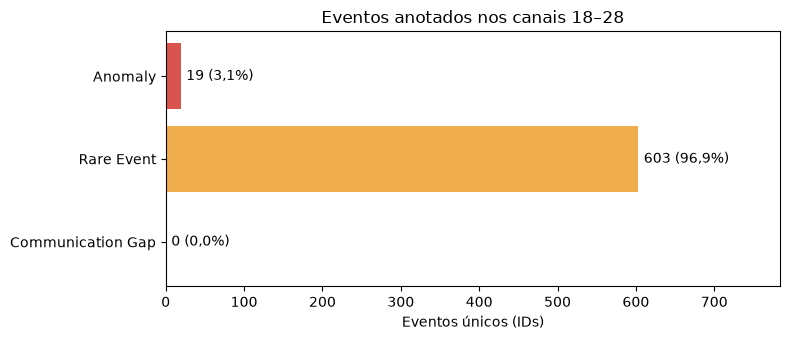

Total: 622 eventos únicos em 5274 intervalos anotados.


In [13]:
ordem_categorias = ["Anomaly", "Rare Event", "Communication Gap"]
contagem_eventos_categoria = eventos_unicos["Category"].value_counts()
categorias_extra = [
    categoria
    for categoria in contagem_eventos_categoria.index
    if categoria not in ordem_categorias
]
ordem_categorias.extend(categorias_extra)
contagem_eventos_categoria = contagem_eventos_categoria.reindex(
    ordem_categorias, fill_value=0
)

resumo_eventos = pd.DataFrame(
    {
        "Categoria": contagem_eventos_categoria.index,
        "Eventos únicos": contagem_eventos_categoria.values,
        "Percentual": (
            contagem_eventos_categoria.values
            / contagem_eventos_categoria.sum()
            * 100
        ).round(1),
    }
)
display(resumo_eventos)

fig, ax = plt.subplots(figsize=(8, 3.5))
bar_colors = [CORES_CATEGORIAS.get(c, "#777777") for c in resumo_eventos["Categoria"]]
bars = ax.barh(resumo_eventos["Categoria"], resumo_eventos["Eventos únicos"], color=bar_colors)
ax.invert_yaxis()
ax.set_xlabel("Eventos únicos (IDs)")
ax.set_title(f"Eventos anotados nos canais {ROTULO_CANAIS}")

rotulos = [
    f"{n} ({p:.1f}%)".replace(".", ",")
    for n, p in zip(resumo_eventos["Eventos únicos"], resumo_eventos["Percentual"])
]
ax.bar_label(bars, labels=rotulos, padding=4)
ax.set_xlim(0, max(resumo_eventos["Eventos únicos"].max() * 1.3, 1))
plt.tight_layout()
plt.show()

print(
    f"Total: {eventos_unicos['ID'].nunique()} eventos únicos "
    f"em {len(labels_clean)} intervalos anotados."
)

**Resposta.** Nos canais 18–28 há **622 eventos únicos**: **19 anomalias (3,1%)**, **603 eventos nominais raros (96,9%)** e **nenhuma lacuna de comunicação**. Eles aparecem em 5.274 intervalos anotados porque um ID pode ter registros em vários canais e em vários trechos.

Em relação à Mission1 (118 eventos: 51 anomalias, 63 raros, 4 lacunas), a Mission2 tem **cinco vezes mais eventos, mas bem menos anomalias**. A classe de interesse é muito rara (cerca de 1 anomalia para 32 eventos raros), o que torna qualquer avaliação sobre anomalias estatisticamente frágil.

**1.2 Qual é o intervalo entre o primeiro início e o último fim anotados de cada anomalia ou evento nominal raro? Como a distribuição se compara?**

> A tabela mostra mediana e quartis em unidades legíveis; o gráfico agrupa os eventos por faixas de tempo. Essa medida é o **envelope dos rótulos** (do primeiro início ao último fim), não necessariamente a duração contínua de um fenômeno. Alguns IDs podem ter intervalos anotados separados; veja a tabela de envelope versus união logo abaixo. `StartTime = EndTime` significa anotação pontual, não duração física zero.

,n,início = fim,mediana,1º quartil,3º quartil,mínimo,máximo
Category,,,,,,,
Anomaly,19,0,1 h 00 min,23 min,1 h 18 min,7 min,19 d 9 h
Rare Event,603,0,46 min,36 min,1 h 19 min,1 min,2 d 1 h


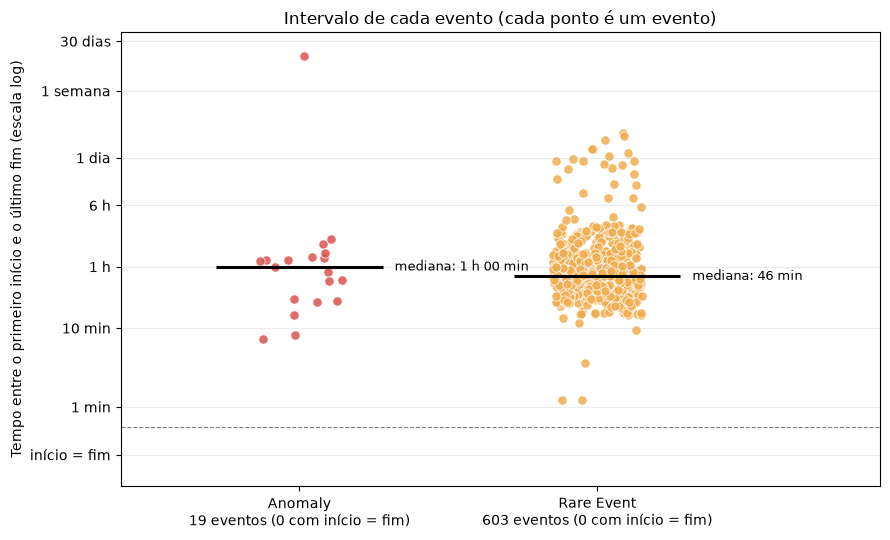

faixa,Menos de 1 min,1 min a 1 h,1 h a 1 dia,Mais de 1 dia
Category,,,,
Anomaly,0,9,9,1
Rare Event,0,389,207,7


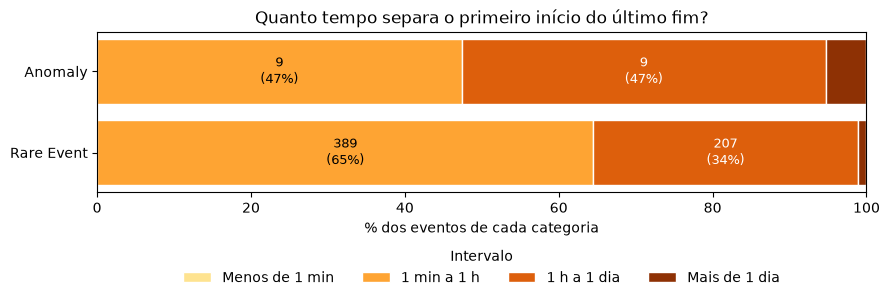

O intervalo é calculado entre datas anotadas e pode incluir trechos sem anotação.
A faixa 'Menos de 1 min' inclui os eventos com início = fim.


In [14]:
categorias_duracao = ["Anomaly", "Rare Event"]
duracoes_eventos = eventos_unicos.loc[
    eventos_unicos["Category"].isin(categorias_duracao),
    ["ID", "Category", "intervalo_total"],
].copy()
duracoes_eventos["horas_entre_datas"] = (
    duracoes_eventos["intervalo_total"].dt.total_seconds() / 3600
)


def formatar_duracao(horas):
    """Escreve uma duração (dada em horas) em unidades fáceis de ler."""
    if pd.isna(horas):
        return "—"
    segundos = horas * 3600
    if segundos == 0:
        return "0 s"
    if segundos < 1:
        return "< 1 s"
    if segundos < 60:
        return f"{segundos:.0f} s"
    minutos_totais = int(round(segundos / 60))
    if minutos_totais < 60:
        return f"{minutos_totais} min"
    if horas < 24:
        h, m = divmod(minutos_totais, 60)
        return f"{h} h {m:02d} min"
    horas_totais = int(round(horas))
    d, h = divmod(horas_totais, 24)
    return f"{d} d {h} h"


# ---------- Tabela-resumo ----------
resumo_duracoes = (
    duracoes_eventos.groupby("Category")["horas_entre_datas"]
    .agg(
        n="count",
        n_zero=lambda valores: int((valores == 0).sum()),
        mediana_horas="median",
        q1_horas=lambda valores: valores.quantile(0.25),
        q3_horas=lambda valores: valores.quantile(0.75),
        minimo_horas="min",
        maximo_horas="max",
    )
    .reindex(categorias_duracao)
)
resumo_duracoes[["n", "n_zero"]] = resumo_duracoes[["n", "n_zero"]].fillna(0)

# A tabela mostra as durações em segundos/minutos/horas/dias, e não em horas arredondadas.
resumo_legivel = resumo_duracoes.copy()
for coluna in ["mediana_horas", "q1_horas", "q3_horas", "minimo_horas", "maximo_horas"]:
    resumo_legivel[coluna] = resumo_legivel[coluna].map(formatar_duracao)
resumo_legivel.columns = ["n", "início = fim", "mediana", "1º quartil", "3º quartil", "mínimo", "máximo"]
display(resumo_legivel)

# ---------- Gráfico A: cada ponto é um evento ----------
positivos = duracoes_eventos.loc[duracoes_eventos["horas_entre_datas"] > 0, "horas_entre_datas"]
menor_positivo = positivos.min() if len(positivos) else 1 / 3600
PISO = menor_positivo / 5          # posição desenhada para os eventos com início = fim
LINHA_SEPARADORA = menor_positivo / 2.2
topo_y = max(duracoes_eventos["horas_entre_datas"].max() * 2, 2.0)

fig, ax = plt.subplots(figsize=(9, 5.5))
rng_duracao = np.random.default_rng(42)
for posicao, categoria in enumerate(categorias_duracao, start=1):
    valores = duracoes_eventos.loc[
        duracoes_eventos["Category"] == categoria, "horas_entre_datas"
    ]
    if valores.empty:
        continue
    y = valores.where(valores > 0, PISO)       # zeros ficam numa faixa própria
    jitter = rng_duracao.uniform(-0.15, 0.15, size=len(y))
    ax.scatter(
        posicao + jitter, y,
        color=CORES_CATEGORIAS[categoria],
        edgecolor="white", linewidth=0.6, alpha=0.85, s=45,
    )
    # traço preto = mediana de cada categoria
    mediana = valores.median()
    y_mediana = max(mediana, PISO)
    ax.hlines(y_mediana, posicao - 0.28, posicao + 0.28, color="black", linewidth=2.2)
    ax.text(
        posicao + 0.32, y_mediana, f"mediana: {formatar_duracao(mediana)}",
        va="center", fontsize=9,
    )

ax.axhline(LINHA_SEPARADORA, color="gray", linestyle="--", linewidth=0.8)
ax.set_yscale("log")
marcas_todas = [PISO, 1/60, 10/60, 1, 6, 24, 168, 720]
nomes_todos = ["início = fim", "1 min", "10 min", "1 h", "6 h", "1 dia", "1 semana", "30 dias"]
ax.set_ylim(PISO / 2.5, topo_y)
marcas_validas = [(m, n) for m, n in zip(marcas_todas, nomes_todos) if m <= topo_y]
ax.set_yticks([m for m, _ in marcas_validas])
ax.set_yticklabels([n for _, n in marcas_validas])
ax.minorticks_off()
ax.set_xlim(0.4, 2.95)
ax.set_xticks([1, 2])
ax.set_xticklabels(
    [
        f"Anomaly\n{int(resumo_duracoes.loc['Anomaly', 'n'])} eventos "
        f"({int(resumo_duracoes.loc['Anomaly', 'n_zero'])} com início = fim)",
        f"Rare Event\n{int(resumo_duracoes.loc['Rare Event', 'n'])} eventos "
        f"({int(resumo_duracoes.loc['Rare Event', 'n_zero'])} com início = fim)",
    ]
)
ax.set_ylabel("Tempo entre o primeiro início e o último fim (escala log)")
ax.set_title("Intervalo de cada evento (cada ponto é um evento)")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# ---------- Gráfico B: resumo por faixas (mais simples de ler) ----------
limites = [-0.1, 1 / 60, 1, 24, np.inf]    # em horas; -0,1 faz o zero entrar na 1ª faixa
rotulos_faixas = ["Menos de 1 min", "1 min a 1 h", "1 h a 1 dia", "Mais de 1 dia"]
duracoes_eventos["faixa"] = pd.cut(
    duracoes_eventos["horas_entre_datas"],
    bins=limites, labels=rotulos_faixas, right=False,
)
tabela_faixas = (
    pd.crosstab(duracoes_eventos["Category"], duracoes_eventos["faixa"])
    .reindex(index=categorias_duracao, columns=rotulos_faixas, fill_value=0)
)
percentuais = tabela_faixas.div(tabela_faixas.sum(axis=1).replace(0, np.nan), axis=0).fillna(0) * 100
display(tabela_faixas)

fig, ax = plt.subplots(figsize=(9, 3.4))
cores_faixas = plt.cm.YlOrBr(np.linspace(0.25, 0.9, len(rotulos_faixas)))
esquerda = np.zeros(len(categorias_duracao))
for i, faixa in enumerate(rotulos_faixas):
    larguras = percentuais[faixa].to_numpy()
    ax.barh(categorias_duracao, larguras, left=esquerda,
            color=cores_faixas[i], edgecolor="white", label=faixa)
    for j, (largura, inicio_barra) in enumerate(zip(larguras, esquerda)):
        if largura >= 6:
            n = int(tabela_faixas.iloc[j][faixa])
            ax.text(
                inicio_barra + largura / 2, j, f"{n}\n({largura:.0f}%)",
                ha="center", va="center", fontsize=9,
                color="white" if i >= 2 else "black",
            )
    esquerda += larguras
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("% dos eventos de cada categoria")
ax.set_title("Quanto tempo separa o primeiro início do último fim?")
ax.legend(title="Intervalo", ncol=4, loc="upper center",
          bbox_to_anchor=(0.5, -0.28), frameon=False)
plt.tight_layout()
plt.show()

print("O intervalo é calculado entre datas anotadas e pode incluir trechos sem anotação.")
print("A faixa 'Menos de 1 min' inclui os eventos com início = fim.")

In [15]:
def duracao_uniao(intervalos):
    intervalos_ordenados = sorted(intervalos, key=lambda par: par[0])
    if not intervalos_ordenados:
        return pd.Timedelta(0)

    inicio_atual, fim_atual = intervalos_ordenados[0]
    duracao_total = pd.Timedelta(0)
    for novo_inicio, novo_fim in intervalos_ordenados[1:]:
        if novo_inicio <= fim_atual:
            fim_atual = max(fim_atual, novo_fim)
        else:
            duracao_total += fim_atual - inicio_atual
            inicio_atual, fim_atual = novo_inicio, novo_fim
    return duracao_total + (fim_atual - inicio_atual)

linhas_duracao_uniao = []
for evento_id, grupo in labels_clean.groupby("ID"):
    pares = list(zip(grupo["StartTimeUTC"], grupo["EndTimeUTC"]))
    linhas_duracao_uniao.append({
        "ID": evento_id,
        "duracao_uniao": duracao_uniao(pares),
    })
duracoes_uniao = pd.DataFrame(linhas_duracao_uniao)
comparacao_duracao = eventos_unicos[["ID", "Category", "intervalo_total"]].merge(
    duracoes_uniao, on="ID", validate="one_to_one"
)
comparacao_duracao["tempo_sem_anotacao_no_envelope"] = (
    comparacao_duracao["intervalo_total"] - comparacao_duracao["duracao_uniao"]
)
if (comparacao_duracao["tempo_sem_anotacao_no_envelope"] < pd.Timedelta(0)).any():
    raise ValueError("A união calculada excede o envelope temporal de algum evento.")
print("Maiores tempos sem anotação dentro do envelope temporal do evento:")
display(
    comparacao_duracao.sort_values(
        "tempo_sem_anotacao_no_envelope", ascending=False
    ).head(10)
)

Maiores tempos sem anotação dentro do envelope temporal do evento:


,ID,Category,intervalo_total,duracao_uniao,tempo_sem_anotacao_no_envelope
556,id_607,Rare Event,0 days 21:50:44.379000,0 days 02:49:16.512000,0 days 19:01:27.867000
584,id_642,Rare Event,0 days 22:03:00.135000,0 days 03:42:00.021000,0 days 18:21:00.114000
536,id_589,Rare Event,0 days 21:51:54.132000,0 days 04:05:08.268000,0 days 17:46:45.864000
441,id_50,Rare Event,0 days 20:06:18.123000,0 days 05:42:18.036000,0 days 14:24:00.087000
562,id_614,Rare Event,0 days 14:59:06.090000,0 days 03:50:42.024000,0 days 11:08:24.066000
100,id_19,Rare Event,0 days 07:23:42.048000,0 days 04:06:00.030000,0 days 03:17:42.018000
510,id_564,Rare Event,0 days 01:21:18.009000,0 days 00:43:30.006000,0 days 00:37:48.003000
134,id_220,Rare Event,0 days 00:43:48.003000,0 days 00:42:36.003000,0 days 00:01:12
135,id_221,Rare Event,0 days 00:42:36.006000,0 days 00:41:24.006000,0 days 00:01:12
506,id_560,Rare Event,0 days 00:57:02.253000,0 days 00:56:08.253000,0 days 00:00:54


**Resposta.**

- **Anomalias (19):** mediana de **1 h 00 min**, metade entre 23 min e 1 h 18 min; mínimo 7 min e máximo **19 d 9 h**. Nenhuma tem início = fim e nenhuma dura menos de 1 min: 9 ficam entre 1 min e 1 h, 9 entre 1 h e 1 dia e 1 passa de 1 dia.
- **Eventos raros (603):** mediana de **46 min**, metade entre 36 min e 1 h 19 min; mínimo 1 min e máximo 2 d 1 h. 389 (64,5%) ficam entre 1 min e 1 h, 207 (34,3%) entre 1 h e 1 dia e 7 (1,2%) passam de 1 dia.
- **Envelope × união:** seis eventos raros (`id_607`, `id_642`, `id_589`, `id_50`, `id_614`, `id_19`) têm de 3 h a 19 h sem anotação dentro do envelope. Neles, o intervalo total não representa a duração real do fenômeno.

**Diferença em relação à Mission1:** lá havia um grupo grande de anomalias muito curtas (29 de 51 com menos de 1 min, 10 com início = fim). Na Mission2 **não há anomalias pontuais**: todas têm um trecho de pelo menos 7 min, e as durações de anomalias e eventos raros são parecidas (mediana 1 h × 46 min). A duração, sozinha, quase não separa as duas classes. Com apenas 19 anomalias, trate isso como observação.

**1.3 Existem eventos que afetam vários canais ao mesmo tempo (mesmo ID em múltiplos canais)? Com que frequência isso acontece?**

Category,Anomaly,Rare Event,Communication Gap
canais_afetados,,,
1,4,1,0
2,7,5,0
3,5,85,0
4,0,11,0
5,0,25,0
6,1,27,0
7,0,82,0
8,1,32,0
9,1,27,0


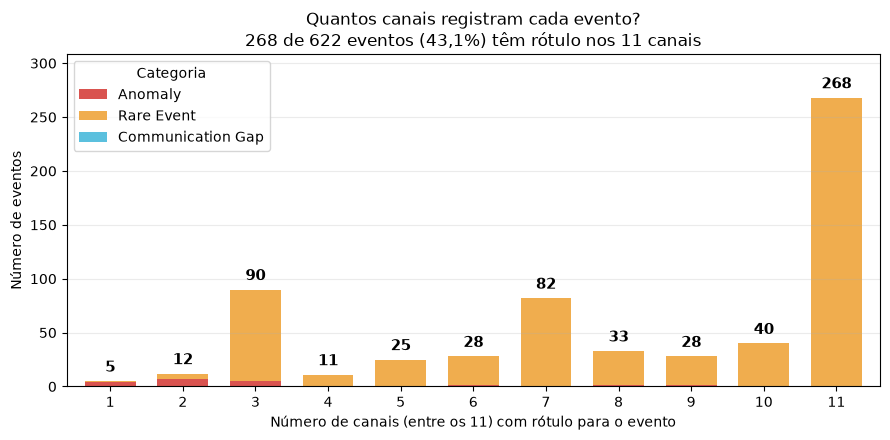

,ID,Category,canais_afetados
548,id_60,Anomaly,1
552,id_603,Anomaly,1
554,id_605,Anomaly,1
583,id_640,Anomaly,1
479,id_535,Rare Event,1
...,...,...,...
477,id_533,Rare Event,10
478,id_534,Rare Event,10
507,id_561,Rare Event,10
541,id_593,Rare Event,10


id_60 (Anomaly): sem rótulo em channel_18, channel_19, channel_20, channel_21, channel_22, channel_23, channel_24, channel_26, channel_27, channel_28.
id_603 (Anomaly): sem rótulo em channel_18, channel_19, channel_20, channel_21, channel_22, channel_23, channel_24, channel_26, channel_27, channel_28.
id_605 (Anomaly): sem rótulo em channel_18, channel_19, channel_20, channel_21, channel_22, channel_23, channel_24, channel_25, channel_27, channel_28.
id_640 (Anomaly): sem rótulo em channel_18, channel_19, channel_20, channel_21, channel_22, channel_23, channel_24, channel_26, channel_27, channel_28.
id_535 (Rare Event): sem rótulo em channel_19, channel_20, channel_21, channel_22, channel_23, channel_24, channel_25, channel_26, channel_27, channel_28.
id_618 (Anomaly): sem rótulo em channel_19, channel_21, channel_22, channel_23, channel_24, channel_25, channel_26, channel_27, channel_28.
id_619 (Anomaly): sem rótulo em channel_19, channel_21, channel_22, channel_23, channel_24, channe

In [16]:
ordem_eventos = (
    eventos_unicos.assign(
        numero_id=eventos_unicos["ID"].str.extract(r"(\d+)", expand=False).astype(int)
    )
    .sort_values(["Category", "numero_id"])
    ["ID"]
    .tolist()
)

# Cada par evento-canal é contado uma vez, mesmo que o canal tenha vários trechos.
eventos_canais = labels_clean[["ID", "Channel"]].drop_duplicates()
matriz_evento_canal = pd.crosstab(
    eventos_canais["ID"], eventos_canais["Channel"]
).reindex(index=ordem_eventos, columns=canais_disponiveis, fill_value=0)
matriz_evento_canal = matriz_evento_canal.gt(0)

resumo_canais_evento = eventos_unicos[["ID", "Category"]].copy()
resumo_canais_evento["canais_afetados"] = matriz_evento_canal.sum(axis=1).reindex(
    resumo_canais_evento["ID"]
).to_numpy()

distribuicao_canais = pd.crosstab(
    resumo_canais_evento["canais_afetados"], resumo_canais_evento["Category"]
).reindex(index=range(1, len(canais_disponiveis) + 1), fill_value=0)
distribuicao_canais = distribuicao_canais.reindex(columns=ordem_categorias, fill_value=0)
display(distribuicao_canais)

n_multicanal = int((resumo_canais_evento["canais_afetados"] > 1).sum())
n_todos_canais = int((resumo_canais_evento["canais_afetados"] == len(canais_disponiveis)).sum())
pct_todos = n_todos_canais / len(eventos_unicos) * 100

# Barras empilhadas, número escrito em cima de TODAS as barras e resumo no título.
fig, ax = plt.subplots(figsize=(9, 4.5))
distribuicao_canais.plot(
    kind="bar", stacked=True, ax=ax, width=0.7,
    color=[CORES_CATEGORIAS.get(c, "#777777") for c in distribuicao_canais.columns],
)
totais = distribuicao_canais.sum(axis=1)
for posicao, total in enumerate(totais):
    ax.text(posicao, total + max(totais.max(), 1) * 0.02, str(int(total)),
            ha="center", va="bottom", fontsize=11, fontweight="bold")
ax.set_ylim(0, max(totais.max(), 1) * 1.15)
ax.set_xlabel(f"Número de canais (entre os {len(canais_disponiveis)}) com rótulo para o evento")
ax.set_ylabel("Número de eventos")
ax.set_title(
    "Quantos canais registram cada evento?\n"
    f"{n_todos_canais} de {len(eventos_unicos)} eventos "
    f"({pct_todos:.1f}%) têm rótulo nos {len(canais_disponiveis)} canais".replace(".", ","),
)
ax.legend(title="Categoria", loc="upper left")
ax.set_xticklabels(distribuicao_canais.index, rotation=0)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

canais_por_id = eventos_canais.groupby("ID")["Channel"].agg(list)
eventos_incompletos = resumo_canais_evento.loc[
    resumo_canais_evento["canais_afetados"] < len(canais_disponiveis)
].copy()
eventos_incompletos = eventos_incompletos.sort_values(["canais_afetados", "Category", "ID"])
display(eventos_incompletos)

for _, linha in eventos_incompletos.head(40).iterrows():
    canais_sem_rotulo = [
        canal for canal in canais_disponiveis if canal not in canais_por_id[linha["ID"]]
    ]
    print(
        f"{linha['ID']} ({linha['Category']}): sem rótulo em "
        f"{', '.join(canais_sem_rotulo)}."
    )
if len(eventos_incompletos) > 40:
    print(f"... (mostrando 40 de {len(eventos_incompletos)} eventos incompletos)")

print(f"Eventos com rótulo em mais de um canal: {n_multicanal} de {len(eventos_unicos)}.")
print(f"Eventos com rótulo nos {len(canais_disponiveis)} canais: {n_todos_canais} de {len(eventos_unicos)}.")
print(f"A tabela lista apenas eventos sem rótulo nos {len(canais_disponiveis)} canais disponíveis.")

**Resposta.** Quase todos os eventos são multicanal: **617 de 622** aparecem em mais de um canal. Só 5 aparecem em um canal (4 anomalias e 1 evento raro).

O número de canais, porém, **difere entre as categorias**:

- **Anomalias:** 16 das 19 (84%) afetam no máximo 3 canais (4 em 1 canal, 7 em 2 e 5 em 3). As outras três afetam 6, 8 e 9 canais. Nenhuma afeta os 11.
- **Eventos raros:** 268 dos 603 (44%) têm rótulo nos **11 canais**; só 91 (15%) afetam 3 canais ou menos.

Isso é o oposto da Mission1, onde 95,8% dos eventos apareciam em todos os 6 canais. É coerente com `anomaly_types.csv`, que marca a maior parte dos eventos como `Global` (585) e poucos como `Local` (59). **Hipótese para a pesquisa:** na Mission2, a quantidade de canais afetados pode ser uma pista para distinguir anomalia (mais local) de evento raro (mais global). Precisa ser confirmada, porque são só 19 anomalias.

"Sem rótulo" significa que não há anotação para aquele ID naquele canal, e não necessariamente que o sinal não mudou.

**1.4 Há concentração de eventos em algum período da linha do tempo anonimizada, ou as ocorrências parecem distribuídas ao longo do recorte?**

Category,Anomaly,Rare Event,Communication Gap
ano_anotado,,,
2000,15,176,0
2001,4,134,0
2002,0,206,0
2003,0,87,0


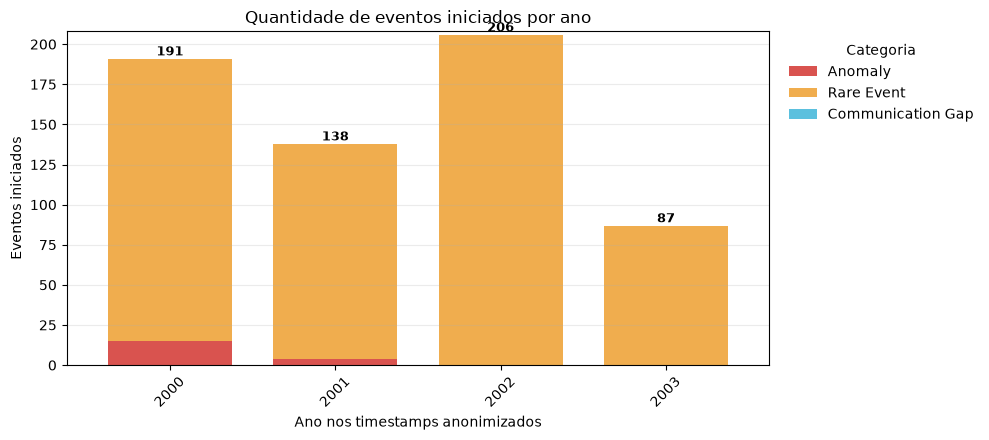

Maior contagem anual: 206 eventos, no(s) ano(s) anotado(s) [2002].
Divisão treino/teste (aproximada): 2001-09-30
Eventos que começam antes: 272 | depois: 350


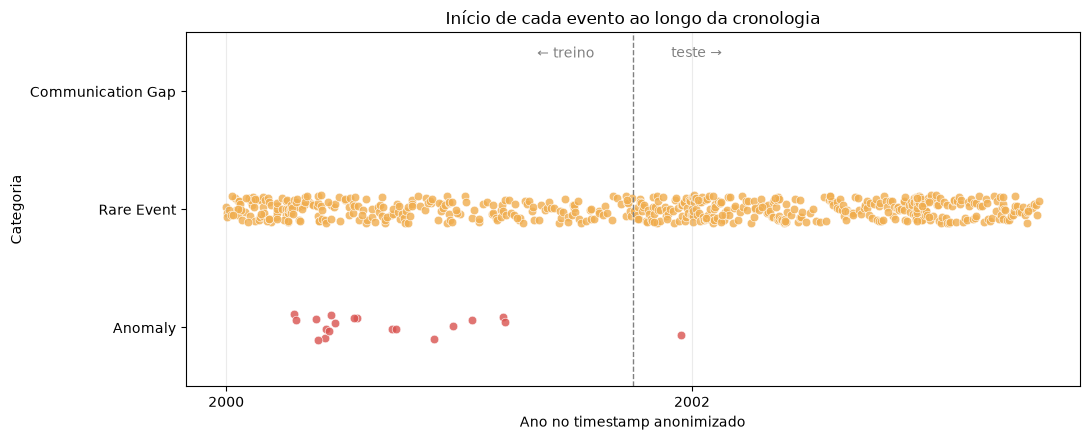

Cada ponto representa o início de um ID; a posição vertical é levemente deslocada apenas para separar pontos próximos. As datas são anonimizadas e não representam o calendário real da missão.

Lacunas de comunicação no recorte: 0


,ID,inicio_utc,fim_utc,intervalo_total


In [17]:
eventos_tempo = eventos_unicos.dropna(subset=["inicio_utc"]).copy()
eventos_tempo["ano_anotado"] = eventos_tempo["inicio_utc"].dt.year
# Para os gráficos de data, usamos o horário sem fuso (evita incompatibilidade com a série).
eventos_tempo["inicio_plot"] = eventos_tempo["inicio_utc"].dt.tz_localize(None)

contagem_anual = pd.crosstab(
    eventos_tempo["ano_anotado"], eventos_tempo["Category"]
).reindex(columns=ordem_categorias, fill_value=0)
anos_completos = range(
    int(eventos_tempo["ano_anotado"].min()),
    int(eventos_tempo["ano_anotado"].max()) + 1,
)
contagem_anual = contagem_anual.reindex(anos_completos, fill_value=0)
display(contagem_anual)

total_por_ano = contagem_anual.sum(axis=1)

# ---------- Gráfico A: eventos por ano ----------
fig, ax = plt.subplots(figsize=(10, 4.5))
contagem_anual.plot(
    kind="bar", stacked=True, ax=ax, width=0.75,
    color=[CORES_CATEGORIAS.get(c, "#777777") for c in contagem_anual.columns],
)
for posicao, total in enumerate(total_por_ano):
    ax.text(posicao, total + 0.15, str(int(total)),
            ha="center", va="bottom", fontsize=9, fontweight="bold")
ax.set_ylim(0, total_por_ano.max() + 2)
ax.set_xlabel("Ano nos timestamps anonimizados")
ax.set_ylabel("Eventos iniciados")
ax.set_title("Quantidade de eventos iniciados por ano")
ax.legend(title="Categoria", loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

max_eventos_ano = int(total_por_ano.max())
anos_pico = total_por_ano.index[total_por_ano == max_eventos_ano].tolist()
print(f"Maior contagem anual: {max_eventos_ano} eventos, no(s) ano(s) anotado(s) {anos_pico}.")

# ---------- Gráfico B: início de cada evento na linha do tempo ----------
# Linha vertical na divisão treino/teste. O artigo usa a primeira metade do período
# para treino; aqui a divisão é o ponto médio da série do canal de referência.
data_corte = ch_ref.index.min() + (ch_ref.index.max() - ch_ref.index.min()) / 2
if data_corte.tzinfo is not None:
    data_corte = data_corte.tz_convert("UTC").tz_localize(None)
antes = int((eventos_tempo["inicio_plot"] < data_corte).sum())
depois = int((eventos_tempo["inicio_plot"] >= data_corte).sum())
print(f"Divisão treino/teste (aproximada): {data_corte.date()}")
print(f"Eventos que começam antes: {antes} | depois: {depois}")

fig, ax = plt.subplots(figsize=(11, 4.5))
rng_tempo = np.random.default_rng(42)
for posicao, categoria in enumerate(ordem_categorias):
    datas_inicio = eventos_tempo.loc[eventos_tempo["Category"] == categoria, "inicio_plot"]
    deslocamento_vertical = rng_tempo.uniform(-0.12, 0.12, size=len(datas_inicio))
    ax.scatter(
        datas_inicio, posicao + deslocamento_vertical,
        color=CORES_CATEGORIAS.get(categoria, "#777777"),
        s=38, alpha=0.8, edgecolor="white", linewidth=0.5,
    )

ax.axvline(data_corte, color="gray", linestyle="--", linewidth=1)
ax.text(data_corte - pd.Timedelta(days=60), 0.96, "← treino", ha="right", va="top",
        transform=ax.get_xaxis_transform(), color="gray", fontsize=10)
ax.text(data_corte + pd.Timedelta(days=60), 0.96, "teste →", ha="left", va="top",
        transform=ax.get_xaxis_transform(), color="gray", fontsize=10)

ax.set_yticks(range(len(ordem_categorias)), ordem_categorias)
ax.set_ylim(-0.5, len(ordem_categorias) - 0.5)
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_xlabel("Ano no timestamp anonimizado")
ax.set_ylabel("Categoria")
ax.set_title("Início de cada evento ao longo da cronologia")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

print(
    "Cada ponto representa o início de um ID; a posição vertical é levemente deslocada "
    "apenas para separar pontos próximos. As datas são anonimizadas e não representam "
    "o calendário real da missão."
)

# ---------- Conferência: datas das lacunas de comunicação ----------
lacunas = eventos_unicos.loc[
    eventos_unicos["Category"] == "Communication Gap",
    ["ID", "inicio_utc", "fim_utc", "intervalo_total"],
]
print(f"\nLacunas de comunicação no recorte: {len(lacunas)}")
display(lacunas)

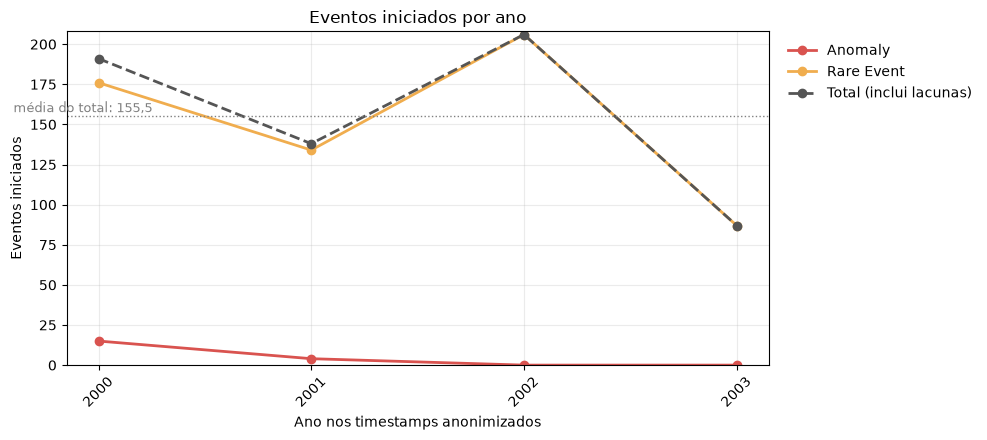

Média anual: 155.5 | mediana: 164.5 | mín–máx: 87–206
Desvio padrão observado entre anos: 46.9 | esperado ao acaso (multinomial): 10.8


Category,Anomaly,Rare Event,Communication Gap,Total
row_0,,,,
1ª metade,18,254,0,272
2ª metade,1,349,0,350


In [18]:
fig, ax = plt.subplots(figsize=(10, 4.5))
anos = contagem_anual.index

for categoria in ["Anomaly", "Rare Event"]:
    ax.plot(anos, contagem_anual[categoria], marker="o", linewidth=2,
            color=CORES_CATEGORIAS[categoria], label=categoria)
ax.plot(anos, total_por_ano, marker="o", linewidth=2, linestyle="--",
        color="#555555", label="Total (inclui lacunas)")

# Linha pontilhada = média anual do total: mostra quais anos ficam acima ou abaixo do normal
media_total = total_por_ano.mean()
ax.axhline(media_total, color="gray", linestyle=":", linewidth=1)
ax.text(anos.min() - 0.4, media_total + 0.25,
        f"média do total: {media_total:.1f}".replace(".", ","),
        fontsize=9, color="gray", va="bottom")

ax.set_xticks(list(anos))
ax.set_xticklabels(anos, rotation=45)
ax.set_ylim(0, total_por_ano.max() + 2)
ax.set_xlabel("Ano nos timestamps anonimizados")
ax.set_ylabel("Eventos iniciados")
ax.set_title("Eventos iniciados por ano")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

# Referência simples: se os eventos fossem sorteados ao acaso entre os anos
n_total = int(total_por_ano.sum())
n_anos = len(total_por_ano)
desvio_esperado_acaso = np.sqrt(n_total * (1 / n_anos) * (1 - 1 / n_anos))
print(f"Média anual: {media_total:.1f} | mediana: {total_por_ano.median():.1f} | "
      f"mín–máx: {int(total_por_ano.min())}–{int(total_por_ano.max())}")
print(f"Desvio padrão observado entre anos: {total_por_ano.std(ddof=0):.1f} | "
      f"esperado ao acaso (multinomial): {desvio_esperado_acaso:.1f}")

# Metade inicial x metade final (corte do gráfico B)
tabela_metades = pd.crosstab(
    np.where(eventos_tempo["inicio_plot"] < data_corte, "1ª metade", "2ª metade"),
    eventos_tempo["Category"],
).reindex(columns=ordem_categorias, fill_value=0)
tabela_metades["Total"] = tabela_metades.sum(axis=1)
display(tabela_metades)

**Resposta.** Sim, os eventos **não** estão distribuídos uniformemente, e isso é o ponto mais importante desta seção.

| Ano | Anomalias | Raros | Total |
|---|---|---|---|
| 2000 | 15 | 176 | 191 |
| 2001 | 4 | 134 | 138 |
| 2002 | 0 | 206 | 206 |
| 2003 (só até 30/06) | 0 | 87 | 87 |

- **Anomalias concentradas no início:** 15 das 19 em 2000 e as outras 4 em 2001; **nenhuma em 2002 ou 2003**.
- **Eventos raros:** presentes em todos os anos, com pico em 2002 (206). Como 2003 cobre só meio ano, 87 em 6 meses é um ritmo semelhante ao de 2001–2002.
- **Variação entre anos:** o desvio padrão observado (46,9) é ~4 vezes o esperado se os eventos fossem sorteados ao acaso entre os anos (10,8), então **a distribuição não é uniforme**. Parte disso vem de o último ano ser parcial.
- **Divisão treino/teste (ponto médio, 2001-09-30):** 272 eventos começam antes (18 anomalias e 254 raros) e 350 depois (**1 anomalia** e 349 raros).

#### 2. Comportamento dos canais durante eventos

**2.1 Como o canal de referência se comporta durante anomalias e eventos raros, comparado com trechos próximos sem rótulo?**

> Para cada intervalo anotado (anomalia ou evento raro) do canal de referência, calculamos o **maior desvio** em relação ao comportamento nominal (mediana e desvio robusto MAD). Para comparação, calculamos o mesmo desvio em um **trecho de controle** de mesma duração, 7 dias antes, que não cruza nenhum rótulo do canal. Ausência de rótulo não garante que o comportamento seja normal.

channel_18: mediana = 0.4560 | escala robusta = 0.00006
Controles descartados por cruzarem algum rótulo: 29


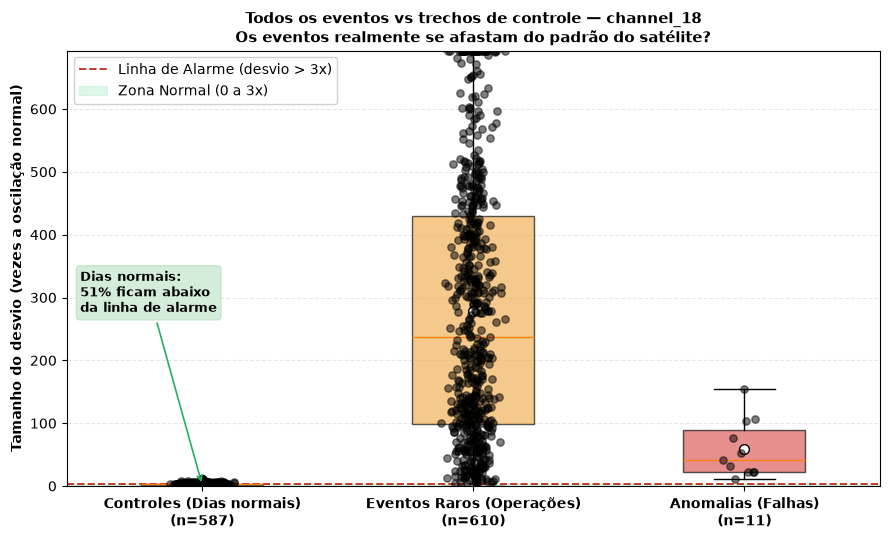

(42 pontos acima de 693x foram cortados no limite superior do gráfico.)
--- Resumo Estatístico Global (Evento × Controle) ---


,Total,Mediana,Alarmariam_Maior_3x
tipo,,,
Controles (Dias normais),587,2.961089,49.2%
Eventos Raros (Operações),610,237.633842,99.8%
Anomalias (Falhas),11,40.834221,100.0%


In [19]:
canal_visual = CANAL_REF
serie_visual = pd.to_numeric(channels[canal_visual].iloc[:, 0], errors="coerce").dropna()


def estimar_nominal(serie: pd.Series, excluir_zeros: bool = True):
    """Mediana e escala robusta (MAD * 1,4826). Se o MAD for 0 (sinal quantizado),
    usa o desvio médio absoluto e, por último, o desvio padrão."""
    base = serie.loc[serie > 0] if excluir_zeros and (serie > 0).sum() > 100 else serie
    mediana = float(base.median())
    escala = 1.4826 * float((base - mediana).abs().median())
    if escala == 0:
        escala = float((base - mediana).abs().mean())
    if escala == 0:
        escala = float(base.std())
    if escala == 0:
        escala = 1.0
    return mediana, escala


# 1. Comportamento normal do canal (mediana e desvio robusto)
mediana_global, mad_global = estimar_nominal(serie_visual)
print(f"{canal_visual}: mediana = {mediana_global:.4f} | escala robusta = {mad_global:.5f}")

# 2. Eventos rotulados deste canal
rotulos_21 = labels_rotuladas.loc[
    (labels_rotuladas["Channel"] == canal_visual)
    & labels_rotuladas["Category"].isin(["Anomaly", "Rare Event"])
].copy()
rotulos_21["inicio"] = para_naive(rotulos_21["StartTimeUTC"])
rotulos_21["fim"] = para_naive(rotulos_21["EndTimeUTC"])

# Todos os rótulos do canal (qualquer categoria): o controle não pode cruzar nenhum
todos_rotulos_canal = labels_clean.loc[labels_clean["Channel"] == canal_visual]
ini_rot = para_naive(todos_rotulos_canal["StartTimeUTC"]).to_numpy()
fim_rot = para_naive(todos_rotulos_canal["EndTimeUTC"]).to_numpy()


def cruza_algum_rotulo(ini, fim):
    return bool(((ini_rot <= np.datetime64(fim)) & (fim_rot >= np.datetime64(ini))).any())


# 3. Desvio máximo para cada evento real e para trechos de controle
registros_comparacao = []
n_controles_descartados = 0

for _, ev in rotulos_21.iterrows():
    trecho_evento = serie_visual.loc[ev["inicio"]: ev["fim"]]
    score_evento = (
        float((trecho_evento - mediana_global).abs().max() / mad_global)
        if len(trecho_evento) > 0 else np.nan
    )
    registros_comparacao.append({
        "tipo": "Anomalias (Falhas)" if ev["Category"] == "Anomaly" else "Eventos Raros (Operações)",
        "desvio_max": score_evento,
    })

    # Trecho de controle com a mesma duração, 7 dias antes
    duracao_ev = ev["fim"] - ev["inicio"]
    ini_ctrl = ev["inicio"] - pd.Timedelta(days=7)
    fim_ctrl = ini_ctrl + duracao_ev
    if cruza_algum_rotulo(ini_ctrl, fim_ctrl):
        n_controles_descartados += 1
        continue
    trecho_ctrl = serie_visual.loc[ini_ctrl:fim_ctrl]
    if len(trecho_ctrl) > 0:
        score_ctrl = float((trecho_ctrl - mediana_global).abs().max() / mad_global)
        registros_comparacao.append({"tipo": "Controles (Dias normais)", "desvio_max": score_ctrl})

df_comp = pd.DataFrame(registros_comparacao).dropna()
print(f"Controles descartados por cruzarem algum rótulo: {n_controles_descartados}")

# ------------------------------------------------------------------------------
# Gráfico Comparativo: Controles vs Eventos Raros vs Anomalias
# ------------------------------------------------------------------------------
ordem_grupos = [
    "Controles (Dias normais)",
    "Eventos Raros (Operações)",
    "Anomalias (Falhas)",
]
cores_grupos = ["#95a5a6", CORES_CATEGORIAS["Rare Event"], CORES_CATEGORIAS["Anomaly"]]
dados_grupos = [df_comp.loc[df_comp["tipo"] == g, "desvio_max"] for g in ordem_grupos]

LIMITE_ALARME = 3
topo_grafico = max(float(np.nanpercentile(df_comp["desvio_max"], 95)) * 1.15, LIMITE_ALARME * 2)
n_acima_do_topo = int((df_comp["desvio_max"] > topo_grafico).sum())

fig, ax = plt.subplots(figsize=(9, 5.5))
bp = ax.boxplot(
    [d.clip(upper=topo_grafico) for d in dados_grupos],
    patch_artist=True,
    widths=0.45,
    showmeans=True,
    meanprops={"marker": "o", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": 7},
)
ax.set_xticks([1, 2, 3])
ax.set_xticklabels([f"{g}\n(n={len(d)})" for g, d in zip(ordem_grupos, dados_grupos)],
                   fontsize=10, fontweight="bold")
for patch, cor in zip(bp["boxes"], cores_grupos):
    patch.set_facecolor(cor)
    patch.set_alpha(0.65)

# Pontos reais individuais
for i, valores in enumerate(dados_grupos):
    rng = np.random.default_rng(42)
    x = rng.normal(i + 1, 0.04, size=len(valores))
    ax.scatter(x, valores.clip(upper=topo_grafico), color="black", alpha=0.5, s=28, zorder=3)

ax.axhline(LIMITE_ALARME, color="#c0392b", linestyle="--", linewidth=1.4,
           label=f"Linha de Alarme (desvio > {LIMITE_ALARME}x)")
ax.axhspan(0, LIMITE_ALARME, color="#2ecc71", alpha=0.15, label=f"Zona Normal (0 a {LIMITE_ALARME}x)")

pct_controle_abaixo = 100 * float((dados_grupos[0] <= LIMITE_ALARME).mean()) if len(dados_grupos[0]) else np.nan
ax.annotate(
    f"Dias normais:\n{pct_controle_abaixo:.0f}% ficam abaixo\nda linha de alarme",
    xy=(1, LIMITE_ALARME * 0.6), xytext=(0.55, topo_grafico * 0.4),
    arrowprops=dict(arrowstyle="->", color="#27ae60", lw=1.2),
    fontsize=9, fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.3", fc="#d4edda", ec="#c3e6cb"),
)
ax.set_ylim(0, topo_grafico)
ax.set_ylabel("Tamanho do desvio (vezes a oscilação normal)", fontsize=10, fontweight="bold")
ax.set_title(f"Todos os eventos vs trechos de controle — {canal_visual}\n"
             "Os eventos realmente se afastam do padrão do satélite?",
             fontsize=11, fontweight="bold")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(loc="upper left", framealpha=0.9)
plt.tight_layout()
plt.show()
if n_acima_do_topo:
    print(f"({n_acima_do_topo} pontos acima de {topo_grafico:.0f}x foram cortados no limite superior do gráfico.)")

# Tabela com as porcentagens de alarme por grupo
resumo_comp = (
    df_comp.groupby("tipo")["desvio_max"]
    .agg(
        Total="count",
        Mediana="median",
        Alarmariam_Maior_3x=lambda s: f"{(s > LIMITE_ALARME).mean()*100:.1f}%",
    )
    .reindex(ordem_grupos)
)
print("--- Resumo Estatístico Global (Evento × Controle) ---")
display(resumo_comp)

Entendendo os dados (todos os números são do `channel_18`; **n conta intervalos anotados**, não eventos):

- **Controles (dias normais, n = 587):** mediana de 2,96x, mas **49,2% ficam acima da linha de 3x**. Ou seja, a linha de alarme de 3 desvios cai no nível do ruído normal deste canal.
- **Eventos raros (n = 610):** mediana de **237,6x**; 99,8% passam de 3x. Um evento raro quase sempre aparece como forte desvio neste canal.
- **Anomalias (n = 11):** mediana de **40,8x**; 100% passam de 3x. Só 11 das 19 anomalias têm intervalo anotado no `channel_18`. 42 pontos ficaram acima de 693x e foram cortados no gráfico.

**Conclusão.** Esta é a **inversão do que se viu na Mission1**: lá as anomalias desviavam mais que os eventos raros; aqui os eventos raros desviam ~6 vezes mais que as anomalias, no valor mediano do desvio. Além disso, a linha de 3x não funciona neste canal: metade dos trechos de controle a cruza, porque a escala robusta é minúscula (≈ 0,00006). Um detector baseado só no valor do `channel_18` gera muitos alertas sem distinguir tipo de evento. 

**2.2 Para cada evento anotado em vários canais, quanto diferem os horários de início registrados em cada canal?**

> A comparação usa o primeiro início anotado por combinação de ID e canal. Um canal sem anotação para aquele ID fica como ausente, não como atraso. Diferenças entre horários anotados não provam que a mudança física do sinal começou exatamente nesses instantes.

Total de eventos que afetam múltiplos canais: 617
Eventos onde todos os canais começam no mesmo segundo: 35 (5.7%)


faixa_atraso,Simultâneo (0s),Até 5 min,Mais de 5 min
Category,,,
Anomaly,4,11,0
Rare Event,31,492,79


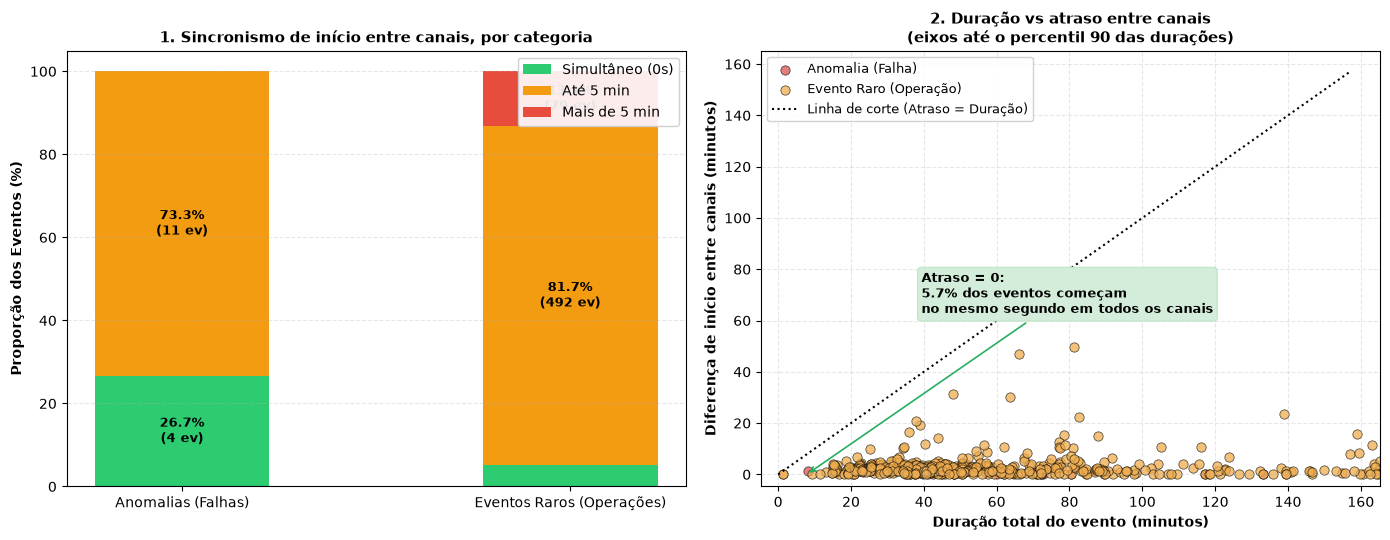


--- 5 Maiores Atrasos Registrados entre Canais ---


,Category,Canais afetados,Atraso máximo (min),Duração total (min)
ID,,,,
id_328,Rare Event,7,876.6,1032.6
id_447,Rare Event,10,661.2,1164.0
id_642,Rare Event,6,636.3,1323.0
id_589,Rare Event,7,636.3,1311.9
id_596,Rare Event,11,633.0,1670.7


In [20]:
# 1. Horário de início anotado em cada canal
inicios_evento_canal = (
    labels_rotuladas.groupby(["ID", "Channel"], as_index=False)
    .agg(inicio_canal=("StartTimeUTC", "min"))
)
inicios_pivot = inicios_evento_canal.pivot(
    index="ID", columns="Channel", values="inicio_canal"
).reindex(columns=canais_disponiveis)

# Apenas eventos que afetam mais de 1 canal
n_canais = inicios_pivot.notna().sum(axis=1)
ids_multi = n_canais[n_canais > 1].index
inicios_multi = inicios_pivot.loc[ids_multi]

# Atraso de cada canal em relação ao primeiro que registrou
primeiro_inicio = inicios_multi.min(axis=1)
atrasos_s = inicios_multi.sub(primeiro_inicio, axis=0).apply(lambda col: col.dt.total_seconds())
atraso_maximo_min = atrasos_s.max(axis=1) / 60  # em minutos

eventos_idx = eventos_unicos.set_index("ID")
df_sincronismo = pd.DataFrame(
    {
        "Category": eventos_idx.loc[ids_multi, "Category"],
        "canais_afetados": n_canais.loc[ids_multi],
        "atraso_max_min": atraso_maximo_min,
        "duracao_total_min": eventos_idx.loc[ids_multi, "intervalo_total"].dt.total_seconds() / 60,
    }
).dropna()
df_sincronismo["mesmo_segundo"] = df_sincronismo["atraso_max_min"] == 0

print(f"Total de eventos que afetam múltiplos canais: {len(df_sincronismo)}")
print(
    f"Eventos onde todos os canais começam no mesmo segundo: {int(df_sincronismo['mesmo_segundo'].sum())} "
    f"({df_sincronismo['mesmo_segundo'].mean()*100:.1f}%)"
)

# ------------------------------------------------------------------------------
# Gráficos: Sincronismo por Categoria e Relação com a Duração
# ------------------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

categorias_analise = ["Anomaly", "Rare Event"]
rotulos_nomes = ["Anomalias (Falhas)", "Eventos Raros (Operações)"]


def classificar_faixa_atraso(minutos):
    if minutos == 0:
        return "Simultâneo (0s)"
    elif minutos <= 5:
        return "Até 5 min"
    return "Mais de 5 min"


df_sincronismo["faixa_atraso"] = df_sincronismo["atraso_max_min"].apply(classificar_faixa_atraso)
ordem_faixas = ["Simultâneo (0s)", "Até 5 min", "Mais de 5 min"]
tabela_faixas_atraso = (
    pd.crosstab(df_sincronismo["Category"], df_sincronismo["faixa_atraso"])
    .reindex(index=categorias_analise, columns=ordem_faixas, fill_value=0)
)
display(tabela_faixas_atraso)
tabela_faixas_pct = (
    tabela_faixas_atraso.div(tabela_faixas_atraso.sum(axis=1).replace(0, np.nan), axis=0).fillna(0) * 100
)

# --- PAINEL 1: proporção de sincronismo por tipo de evento ---
cores_empilhadas = ["#2ecc71", "#f39c12", "#e74c3c"]
bottom = np.zeros(len(categorias_analise))
for i, faixa in enumerate(ordem_faixas):
    valores = tabela_faixas_pct[faixa].values
    ax1.bar(rotulos_nomes, valores, bottom=bottom, label=faixa, color=cores_empilhadas[i], width=0.45)
    for j, val in enumerate(valores):
        if val > 6:
            ax1.text(j, bottom[j] + val / 2, f"{val:.1f}%\n({tabela_faixas_atraso.iloc[j, i]} ev)",
                     ha="center", va="center", color="black", fontsize=9, fontweight="bold")
    bottom += valores
ax1.set_ylabel("Proporção dos Eventos (%)", fontsize=10, fontweight="bold")
ax1.set_title("1. Sincronismo de início entre canais, por categoria", fontsize=11, fontweight="bold")
ax1.set_ylim(0, 105)
ax1.legend(loc="upper right", framealpha=0.9)
ax1.grid(axis="y", linestyle="--", alpha=0.3)

# --- PAINEL 2: duração do evento vs atraso entre canais ---
for cat in categorias_analise:
    sub = df_sincronismo[df_sincronismo["Category"] == cat]
    ax2.scatter(
        sub["duracao_total_min"], sub["atraso_max_min"],
        color=CORES_CATEGORIAS[cat],
        label="Anomalia (Falha)" if cat == "Anomaly" else "Evento Raro (Operação)",
        alpha=0.75, s=45, edgecolor="black", linewidth=0.5,
    )

# Eixos limitados ao percentil 90 das durações (os eventos mais longos ficam fora da vista)
limite_eixo = max(float(np.nanpercentile(df_sincronismo["duracao_total_min"], 90)), 10.0)
ax2.plot([0, limite_eixo], [0, limite_eixo], color="black", linestyle=":", linewidth=1.5,
         label="Linha de corte (Atraso = Duração)")
ax2.set_xlim(-limite_eixo * 0.03, limite_eixo * 1.05)
ax2.set_ylim(-limite_eixo * 0.03, limite_eixo * 1.05)
ax2.set_xlabel("Duração total do evento (minutos)", fontsize=10, fontweight="bold")
ax2.set_ylabel("Diferença de início entre canais (minutos)", fontsize=10, fontweight="bold")
ax2.set_title("2. Duração vs atraso entre canais\n(eixos até o percentil 90 das durações)", fontsize=11, fontweight="bold")
ax2.grid(True, linestyle="--", alpha=0.3)
ax2.legend(loc="upper left", framealpha=0.9, fontsize=9)

pct_zero = 100 * df_sincronismo["mesmo_segundo"].mean()
ax2.annotate(
    f"Atraso = 0:\n{pct_zero:.1f}% dos eventos começam\nno mesmo segundo em todos os canais",
    xy=(limite_eixo * 0.05, 0), xytext=(limite_eixo * 0.25, limite_eixo * 0.4),
    arrowprops=dict(arrowstyle="->", color="#27ae60", lw=1.2),
    fontsize=9, fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.3", fc="#d4edda", ec="#c3e6cb"),
)
plt.tight_layout()
plt.show()

print("\n--- 5 Maiores Atrasos Registrados entre Canais ---")
display(
    df_sincronismo.sort_values("atraso_max_min", ascending=False)
    .head(5)[["Category", "canais_afetados", "atraso_max_min", "duracao_total_min"]]
    .rename(columns={
        "canais_afetados": "Canais afetados",
        "atraso_max_min": "Atraso máximo (min)",
        "duracao_total_min": "Duração total (min)",
    })
    .round(1)
)

**Resultado do sincronismo entre canais** (617 eventos multicanal):

| Categoria | Mesmo segundo | Até 5 min | Mais de 5 min |
|---|---|---|---|
| Anomalias (15) | 4 (26,7%) | 11 (73,3%) | 0 |
| Eventos raros (602) | 31 (5,1%) | 492 (81,7%) | 79 (13,1%) |

- Só **35 dos 617 eventos (5,7%)** começam no mesmo segundo em todos os canais. Na Mission1 eram 67,5% (e ~80% das anomalias).
- **Anomalias:** nenhuma tem atraso acima de 5 min, mas apenas 4 de 15 são simultâneas ao segundo. Há uma defasagem pequena (até 5 min) na maioria.
- **Eventos raros:** 79 (13,1%) passam de 5 min de atraso, e os **5 maiores atrasos são todos de eventos raros**, de 10,5 h a 14,6 h (`id_328`: 876,6 min). Isso lembra o padrão da Mission1 (atrasos longos em operações), mas a maioria dos raros também começa em até 5 min.

**Conclusão.** O sincronismo ao segundo **não** é uma pista forte na Mission2 (só 5,7% dos eventos). O que sobra é um sinal fraco: atrasos acima de 5 min só aparecem em eventos raros (0 de 15 anomalias, contra 13% dos raros). Com 15 anomalias, não dá para chamar de regra. Como o início de cada canal vem dos rótulos, parte da diferença pode ser efeito da anotação.

**2.3 Há sequências em que o canal registra o mesmo valor por vários minutos ou horas? Com que frequência e duração aparecem?**

> Uma sequência é interrompida se o valor mudar ou se houver uma pausa de coleta maior que **10 vezes o intervalo mediano** (na Mission1, 5 min = 10 × 30 s). Contamos sequências com pelo menos 4 leituras e 10 minutos de duração. Repetição de valores, por si só, não prova que o sensor travou; pode ser efeito da quantização do sinal.

Pausa que quebra a sequência: 180 s


,sequencias_>=10min,sequencias_>=1h,sequencias_>=6h,maior_duracao_h,valor_da_maior
canal,,,,,
channel_18,1,1,0,1.27,0.46
channel_19,1,1,0,1.27,0.46
channel_20,1,1,0,1.27,0.46
channel_21,0,0,0,0.00,NaN
channel_22,0,0,0,0.00,NaN
channel_23,0,0,0,0.00,NaN
channel_24,0,0,0,0.00,NaN
channel_25,0,0,0,0.00,NaN
channel_26,0,0,0,0.00,NaN



Total de sequências de valor constante (>= 10 min) em channel_18: 1
--- Maiores sequências encontradas ---


,valor,inicio,fim,duracao_minutos,n_leituras,intervalo_medio_s
0,0.456,2000-05-24 23:53:31.257,2000-05-25 01:09:59.022,76.5,332,13.8


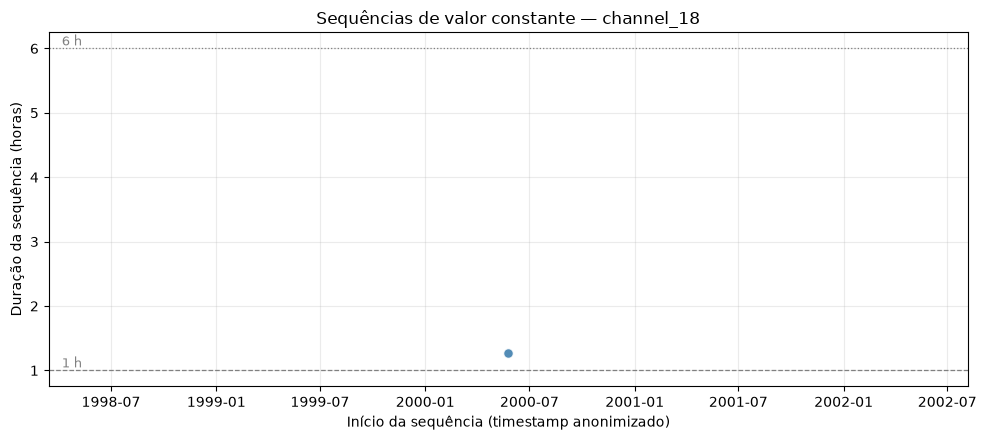

In [21]:
LIMITE_PAUSA_SEQ_S = 10 * MEDIANA_AMOSTRAGEM_S
MIN_LEITURAS_SEQ = 4
MIN_DURACAO_SEQ_MIN = 10


def sequencias_constantes(serie: pd.Series, limite_pausa_s: float,
                          min_leituras: int = MIN_LEITURAS_SEQ,
                          min_duracao_min: float = MIN_DURACAO_SEQ_MIN) -> pd.DataFrame:
    """Sequências de leituras idênticas, quebradas por mudança de valor ou pausa longa."""
    valores = serie.to_numpy()
    ts = indice_ns(serie.index)
    quebra = np.zeros(len(valores), dtype=bool)
    quebra[1:] = (valores[1:] != valores[:-1]) | ((np.diff(ts) / 1e9) > limite_pausa_s)
    inicios = np.flatnonzero(np.r_[True, quebra[1:]])
    fins = np.r_[inicios[1:] - 1, len(valores) - 1]
    n_leituras = fins - inicios + 1
    duracao_min = (ts[fins] - ts[inicios]) / 1e9 / 60
    tabela = pd.DataFrame({
        "valor": valores[inicios],
        "inicio": serie.index[inicios],
        "fim": serie.index[fins],
        "n_leituras": n_leituras,
        "duracao_minutos": duracao_min,
    })
    filtro = (tabela["n_leituras"] >= min_leituras) & (tabela["duracao_minutos"] >= min_duracao_min)
    return tabela.loc[filtro].sort_values("duracao_minutos", ascending=False).reset_index(drop=True)


sequencias_por_canal = {}
linhas_seq = []
for nome, df in channels.items():
    serie_n = pd.to_numeric(df.iloc[:, 0], errors="coerce").dropna().sort_index()
    seq = sequencias_constantes(serie_n, LIMITE_PAUSA_SEQ_S)
    sequencias_por_canal[nome] = seq
    linhas_seq.append({
        "canal": nome,
        "sequencias_>=10min": len(seq),
        "sequencias_>=1h": int((seq["duracao_minutos"] >= 60).sum()),
        "sequencias_>=6h": int((seq["duracao_minutos"] >= 360).sum()),
        "maior_duracao_h": float(seq["duracao_minutos"].max() / 60) if len(seq) else 0.0,
        "valor_da_maior": seq["valor"].iloc[0] if len(seq) else np.nan,
    })
resumo_sequencias = pd.DataFrame(linhas_seq).set_index("canal")
print(f"Pausa que quebra a sequência: {LIMITE_PAUSA_SEQ_S:g} s")
display(resumo_sequencias.round(2))

sequencias_longas = sequencias_por_canal[CANAL_REF].copy()
sequencias_longas["intervalo_medio_s"] = (
    sequencias_longas["duracao_minutos"] * 60 / sequencias_longas["n_leituras"]
)
print(f"\nTotal de sequências de valor constante (>= {MIN_DURACAO_SEQ_MIN} min) em {CANAL_REF}: {len(sequencias_longas)}")
print("--- Maiores sequências encontradas ---")
display(
    sequencias_longas[["valor", "inicio", "fim", "duracao_minutos", "n_leituras", "intervalo_medio_s"]]
    .head(6).round({"valor": 3, "duracao_minutos": 1, "intervalo_medio_s": 1})
)

# Gráfico: cada sequência é um ponto (duração em horas, escala linear)
fig, ax = plt.subplots(figsize=(10, 4.5))
if len(sequencias_longas):
    ax.scatter(sequencias_longas["inicio"], sequencias_longas["duracao_minutos"] / 60,
               color="#3578aa", edgecolor="white", s=50, alpha=0.85)
ax.axhline(1, color="gray", linestyle="--", linewidth=0.9)
ax.axhline(6, color="gray", linestyle=":", linewidth=0.9)
ax.text(0.01, 1, " 1 h", transform=ax.get_yaxis_transform(), va="bottom", color="gray", fontsize=9)
ax.text(0.01, 6, " 6 h", transform=ax.get_yaxis_transform(), va="bottom", color="gray", fontsize=9)
ax.set_ylabel("Duração da sequência (horas)")
ax.set_xlabel("Início da sequência (timestamp anonimizado)")
ax.set_title(f"Sequências de valor constante — {CANAL_REF}")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Resultado.** Há **uma única sequência** de valor constante de pelo menos 10 min (limite de quebra: pausa > 180 s), e ela aparece **só nos canais 18, 19 e 20**: 76,5 min (1,27 h), com 332 leituras, de 2000-05-24 23:53 a 2000-05-25 01:09. Os canais 21–28 não têm nenhuma.

- O valor repetido é **0,456**, o mesmo valor nominal do `channel_18` (mediana 0,45602). Não é um valor "congelado" fora do padrão (como o 0,210 da Mission1) nem zero: é um trecho muito quieto do sinal. Repetir valores aqui não indica travamento.
- A data coincide com o dia em que aparecem 9 das 10 maiores pausas de coleta (seção 2.4). Isso é só coincidência de data; a relação não foi investigada.
- Diferente da Mission1 (4 a 10 sequências por canal, até 77 h, com zeros em 2009), a Mission2 praticamente não tem sequências constantes longas.

**2.4 Qual é o intervalo mais comum entre leituras nos canais 18–28? Os horários coincidem entre canais? Em que momentos aparecem pausas longas?**

> O gráfico mostra os intervalos mais frequentes no canal de referência como percentual de todos os intervalos. A tabela resume pausas maiores que limites exploratórios; uma pausa entre timestamps não equivale a uma célula nula nem confirma perda de dados.

--- Intervalos mais comuns entre leituras (Top 5) ---


,intervalo_segundos,contagem,percentual
169,18.00,4727529,64.00
32,2.25,653866,8.85
150,15.75,641843,8.69
151,15.75,581159,7.87
31,2.25,569287,7.71


Quantidade de valores distintos de intervalo: 185

--- Os timestamps coincidem com os do canal de referência? ---


,mesmo_indice,n_leituras
canal,,
channel_18,True,7387262
channel_19,True,7387262
channel_20,True,7387262
channel_21,True,7387262
channel_22,True,7387262
channel_23,True,7387262
channel_24,True,7387262
channel_25,True,7387262
channel_26,True,7387262


,pausas > 5 min,pausas > 1 h,pausas > 6 h,pausas > 1 dia,maior_pausa_h
canal,,,,,
channel_18,1,0,0,0,0.63
channel_19,1,0,0,0,0.63
channel_20,1,0,0,0,0.63
channel_21,1,0,0,0,0.63
channel_22,1,0,0,0,0.63
channel_23,1,0,0,0,0.63
channel_24,1,0,0,0,0.63
channel_25,1,0,0,0,0.63
channel_26,1,0,0,0,0.63



--- Maior pausa contínua registrada (channel_18) ---
Início: 2001-10-21 21:47:15.825000  →  Fim: 2001-10-21 22:25:03.828000 (Duração: 0.63 horas)

--- 10 maiores pausas e eventos anotados coincidentes ---


,inicio,fim,duracao_h,evento_anotado_coincidente
0,2001-10-21 21:47:15.825,2001-10-21 22:25:03.828,0.63,—
1,2000-05-25 15:32:13.356,2000-05-25 15:34:19.359,0.04,—
2,2000-05-25 11:28:55.332,2000-05-25 11:30:25.332,0.02,—
3,2000-05-25 03:22:37.284,2000-05-25 03:24:07.284,0.02,—
4,2000-05-25 19:11:13.380,2000-05-25 19:12:28.380,0.02,—
5,2000-05-25 06:04:55.299,2000-05-25 06:06:07.299,0.02,—
6,2000-05-25 18:55:37.377,2000-05-25 18:56:29.130,0.01,—
7,2000-05-25 02:01:01.275,2000-05-25 02:01:37.275,0.01,—
8,2000-05-25 12:50:31.341,2000-05-25 12:51:07.341,0.01,—
9,2000-05-25 18:52:55.377,2000-05-25 18:53:31.377,0.01,—


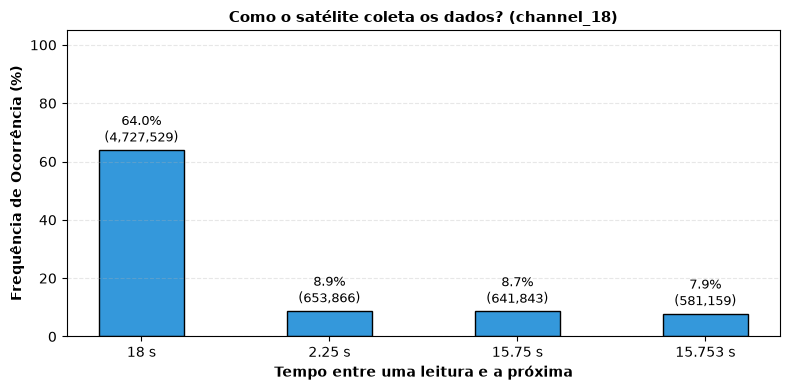

In [22]:
canal_referencia = CANAL_REF
serie_ref = channels[canal_referencia]

intervalos_segundos = intervalos_em_segundos(serie_ref.index)

# 1. Tabela dos intervalos mais frequentes
valores_comuns, contagens = np.unique(np.round(intervalos_segundos, 3), return_counts=True)
df_intervalos = pd.DataFrame(
    {"intervalo_segundos": valores_comuns, "contagem": contagens}
).sort_values("contagem", ascending=False)
df_intervalos["percentual"] = df_intervalos["contagem"] / len(intervalos_segundos) * 100

print("--- Intervalos mais comuns entre leituras (Top 5) ---")
display(df_intervalos.head(5).round(2))
print(f"Quantidade de valores distintos de intervalo: {len(df_intervalos)}")

# 2. Os timestamps coincidem entre canais?
print("\n--- Os timestamps coincidem com os do canal de referência? ---")
coincidencia = pd.DataFrame({
    "canal": list(channels),
    "mesmo_indice": [df.index.equals(serie_ref.index) for df in channels.values()],
    "n_leituras": [len(df) for df in channels.values()],
}).set_index("canal")
display(coincidencia)

# 3. Sensibilidade ao limite de pausa (por canal)
limites_pausa_s = {"5 min": 300, "1 h": 3600, "6 h": 6 * 3600, "1 dia": 86400}
linhas_pausas_limite = []
for nome, df in channels.items():
    difs = intervalos_em_segundos(df.index)
    linha = {"canal": nome}
    for rotulo, lim in limites_pausa_s.items():
        linha[f"pausas > {rotulo}"] = int((difs > lim).sum())
    linha["maior_pausa_h"] = float(difs.max() / 3600)
    linhas_pausas_limite.append(linha)
display(pd.DataFrame(linhas_pausas_limite).set_index("canal").round(2))

# 4. Maior pausa e as 10 maiores pausas do canal de referência
indice_maior = int(np.argmax(intervalos_segundos))
inicio_pausa = serie_ref.index[indice_maior]
fim_pausa = serie_ref.index[indice_maior + 1]
duracao_pausa_horas = intervalos_segundos[indice_maior] / 3600
print(f"\n--- Maior pausa contínua registrada ({canal_referencia}) ---")
print(f"Início: {inicio_pausa}  →  Fim: {fim_pausa} (Duração: {duracao_pausa_horas:.2f} horas)")

top_pausas = np.argsort(intervalos_segundos)[::-1][:10]
tabela_top_pausas = pd.DataFrame({
    "inicio": serie_ref.index[top_pausas],
    "fim": serie_ref.index[top_pausas + 1],
    "duracao_h": intervalos_segundos[top_pausas] / 3600,
})
# Cruzamento com rótulos: cada pausa coincide com algum evento anotado?
rotulos_canal_ref = labels_rotuladas.loc[labels_rotuladas["Channel"] == canal_referencia].copy()
rotulos_canal_ref["inicio"] = para_naive(rotulos_canal_ref["StartTimeUTC"])
rotulos_canal_ref["fim"] = para_naive(rotulos_canal_ref["EndTimeUTC"])


def evento_na_pausa(ini, fim):
    achados = rotulos_canal_ref.loc[
        (rotulos_canal_ref["inicio"] <= fim) & (rotulos_canal_ref["fim"] >= ini), ["ID", "Category"]
    ]
    return "; ".join(f"{r.ID} ({r.Category})" for r in achados.itertuples()) or "—"


tabela_top_pausas["evento_anotado_coincidente"] = [
    evento_na_pausa(r.inicio, r.fim) for r in tabela_top_pausas.itertuples()
]
print("\n--- 10 maiores pausas e eventos anotados coincidentes ---")
display(tabela_top_pausas.round({"duracao_h": 2}))

# ------------------------------------------------------------------------------
# Gráfico dos intervalos mais comuns
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 4))
top4 = df_intervalos.head(4).copy()
top4["label"] = top4["intervalo_segundos"].apply(lambda s: f"{s:g} s")
barras = ax.bar(top4["label"], top4["percentual"], color="#3498db", edgecolor="black", width=0.45)
ax.bar_label(
    barras,
    labels=[f"{p:.1f}%\n({n:,})" for p, n in zip(top4["percentual"], top4["contagem"])],
    padding=3, fontsize=9,
)
ax.set_ylabel("Frequência de Ocorrência (%)", fontsize=10, fontweight="bold")
ax.set_xlabel("Tempo entre uma leitura e a próxima", fontsize=10, fontweight="bold")
ax.set_title(f"Como o satélite coleta os dados? ({canal_referencia})", fontsize=11, fontweight="bold")
ax.set_ylim(0, 105)
ax.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

**Resultado.** O intervalo mediano é de **18 s**, e **64,0%** dos intervalos têm exatamente esse valor. Os outros dois mais frequentes são ≈ 2,25 s e ≈ 15,75 s: cada um aparece duas vezes no top 5 (provavelmente por variações de milissegundos) e soma ≈ 16,6%. Juntos, 18 s, 2,25 s e 15,75 s cobrem ≈ 97% dos intervalos. Como 18 = 8 × 2,25 e 15,75 = 7 × 2,25, a coleta parece seguir uma **grade de 2,25 s**, a ser confirmada. Há 185 valores distintos de intervalo.

- **Os timestamps coincidem em todos os 11 canais** (mesmo índice, 7.387.262 leituras), como na Mission1.
- **Pausas:** só **uma** acima de 5 min, de 37,8 min (0,63 h), em 2001-10-21 (21:47 → 22:25), e **nenhuma** acima de 1 h. Na Mission1 a maior pausa era de 5,91 h. Essa pausa não coincide com nenhum evento anotado. As outras 9 das 10 maiores são curtas (de 36 s a 2 min) e acontecem todas em 2000-05-25, também sem evento coincidente.


#### 3. Telecomandos e contexto operacional

**3.1 Quantos telecomandos diferentes foram executados ao longo do período? Quais são os mais frequentes?**

Arquivos ZIP de histórico: 123
IDs no catálogo: 123
Tipos com ao menos uma execução no período: 123
Arquivos sem correspondência no catálogo: 0
IDs do catálogo sem arquivo ZIP: 0


/tmp/ipykernel_117076/4121070628.py:41: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  return pickle.loads(z.read(nome_arquivo))


,Telecommand,execucoes_no_periodo,registros_no_arquivo,indice_ordenado,timestamps_duplicados,Priority
21,telecommand_118,92460,92460,True,0,2
111,telecommand_89,89358,89358,True,0,2
20,telecommand_117,88283,88283,True,0,2
66,telecommand_48,85920,85920,True,0,2
7,telecommand_105,84337,84337,True,0,2
63,telecommand_45,82738,82738,True,0,2
10,telecommand_108,78358,78358,True,0,2
11,telecommand_109,77892,77892,True,0,2
14,telecommand_111,75336,75336,True,0,2
9,telecommand_107,72247,72247,True,0,2


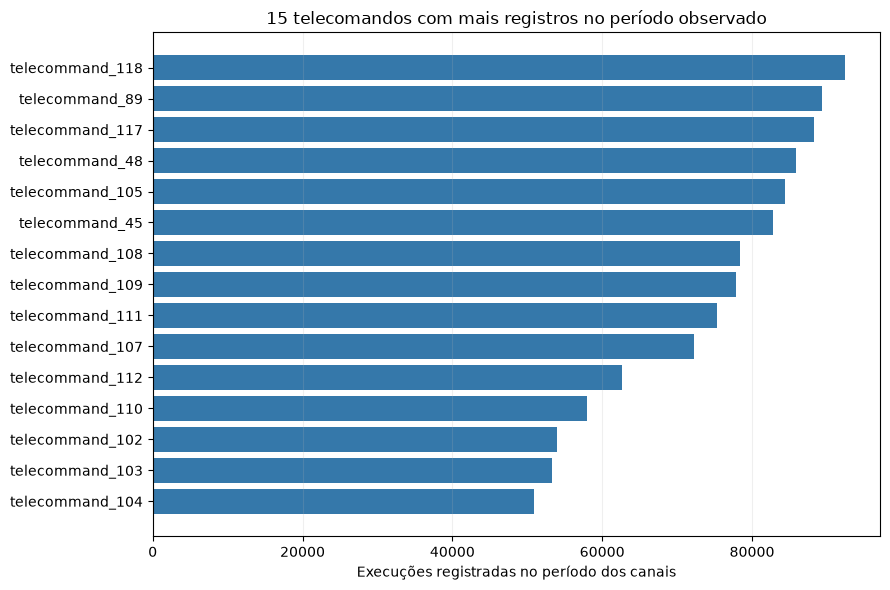

In [23]:
if not {"Telecommand", "Priority"}.issubset(tc_meta.columns):
    raise KeyError(f"Colunas inesperadas no catálogo: {tc_meta.columns.tolist()}")
if tc_meta["Telecommand"].duplicated().any():
    raise ValueError("Há IDs de telecomando duplicados no catálogo.")

inicio_observado = ch_ref.index.min()
fim_observado = ch_ref.index.max()
if getattr(inicio_observado, "tzinfo", None) is not None:
    inicio_observado = inicio_observado.tz_convert("UTC").tz_localize(None)
    fim_observado = fim_observado.tz_convert("UTC").tz_localize(None)

linhas_contagem_tc = []
for caminho in arquivos_tc:
    tabela_tc = load_zip_pickle(caminho)
    indice_tc = tabela_tc.index
    if not isinstance(indice_tc, pd.DatetimeIndex):
        raise TypeError(f"Índice temporal inesperado em {caminho.name}.")
    if indice_tc.tz is not None:
        indice_tc = indice_tc.tz_convert("UTC").tz_localize(None)

    if indice_tc.is_monotonic_increasing:
        inicio_pos = indice_tc.searchsorted(inicio_observado, side="left")
        fim_pos = indice_tc.searchsorted(fim_observado, side="right")
        execucoes_periodo = int(fim_pos - inicio_pos)
    else:
        execucoes_periodo = int(((indice_tc >= inicio_observado) & (indice_tc <= fim_observado)).sum())
    linhas_contagem_tc.append({
        "Telecommand": caminho.stem,
        "execucoes_no_periodo": execucoes_periodo,
        "registros_no_arquivo": len(tabela_tc),
        "indice_ordenado": indice_tc.is_monotonic_increasing,
        "timestamps_duplicados": int(indice_tc.duplicated().sum()),
    })
    del tabela_tc

tc_contagens = pd.DataFrame(linhas_contagem_tc)
contagens_tc = tc_contagens.merge(
    tc_meta[["Telecommand", "Priority"]],
    on="Telecommand", how="outer", validate="one_to_one", indicator=True,
)
sem_catalogo = contagens_tc.loc[contagens_tc["_merge"] == "left_only", "Telecommand"].tolist()
sem_arquivo = contagens_tc.loc[contagens_tc["_merge"] == "right_only", "Telecommand"].tolist()
contagens_tc = contagens_tc.drop(columns="_merge").sort_values(
    "execucoes_no_periodo", ascending=False, na_position="last"
)

print(f"Arquivos ZIP de histórico: {len(arquivos_tc)}")
print(f"IDs no catálogo: {len(tc_meta)}")
print(f"Tipos com ao menos uma execução no período: {int((contagens_tc['execucoes_no_periodo'] > 0).sum())}")
print(f"Arquivos sem correspondência no catálogo: {len(sem_catalogo)}")
print(f"IDs do catálogo sem arquivo ZIP: {len(sem_arquivo)}")
display(contagens_tc.head(15))

mais_frequentes_tc = contagens_tc.dropna(subset=["execucoes_no_periodo"]).head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(mais_frequentes_tc["Telecommand"], mais_frequentes_tc["execucoes_no_periodo"], color="#3578aa")
ax.set_xlabel("Execuções registradas no período dos canais")
ax.set_title("15 telecomandos com mais registros no período observado")
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
plt.show()

**3.2 Existe algum telecomando que aparece frequentemente nas horas ou dias que antecedem eventos nominais raros nos canais 18–28?**

In [24]:
duracoes_janela_h = [1, 6, 24]
inicio_telemetria = inicio_observado
rotulos_utc = labels_clean[["ID", "Channel", "StartTimeUTC", "EndTimeUTC"]].copy()
rotulos_utc["inicio"] = para_naive(rotulos_utc["StartTimeUTC"])
rotulos_utc["fim"] = para_naive(rotulos_utc["EndTimeUTC"])

eventos_contexto = eventos_unicos.loc[
    eventos_unicos["Category"].isin(["Anomaly", "Rare Event"]),
    ["ID", "Category", "inicio_utc"],
].copy()
eventos_contexto["inicio"] = eventos_contexto["inicio_utc"].dt.tz_convert(None)

janelas_evento = []
for evento in eventos_contexto.itertuples(index=False):
    for horas in duracoes_janela_h:
        inicio = evento.inicio - pd.Timedelta(hours=horas)
        if inicio >= inicio_telemetria:
            janelas_evento.append({
                "ID": evento.ID, "Category": evento.Category, "tipo_janela": "evento",
                "horas": horas, "inicio": inicio, "fim": evento.inicio,
            })
janelas_evento = pd.DataFrame(janelas_evento)

# Janelas de referência: mesma duração, semanas antes, sem cruzar rótulos nem outras janelas
janelas_referencia = []
for janela in janelas_evento.itertuples(index=False):
    duracao = pd.Timedelta(hours=janela.horas)
    achou_referencia = False
    for semanas_antes in range(1, 53):
        fim_candidato = janela.inicio - pd.Timedelta(weeks=semanas_antes)
        inicio_candidato = fim_candidato - duracao
        if inicio_candidato < inicio_telemetria:
            break
        cruza_rotulo = (
            (rotulos_utc["inicio"] < fim_candidato) & (rotulos_utc["fim"] > inicio_candidato)
        ).any()
        cruza_evento = (
            (janelas_evento["horas"] == janela.horas)
            & (janelas_evento["inicio"] < fim_candidato)
            & (janelas_evento["fim"] > inicio_candidato)
        ).any()
        cruza_referencia = any(
            ref["horas"] == janela.horas and ref["inicio"] < fim_candidato and ref["fim"] > inicio_candidato
            for ref in janelas_referencia
        )
        if not cruza_rotulo and not cruza_evento and not cruza_referencia:
            janelas_referencia.append({
                "ID": janela.ID, "Category": janela.Category, "tipo_janela": "referencia",
                "horas": janela.horas, "inicio": inicio_candidato, "fim": fim_candidato,
            })
            achou_referencia = True
            break
    if not achou_referencia:
        janelas_referencia.append({
            "ID": janela.ID, "Category": janela.Category, "tipo_janela": "referencia_indisponivel",
            "horas": janela.horas, "inicio": pd.NaT, "fim": pd.NaT,
        })

janelas_analise = pd.concat([janelas_evento, pd.DataFrame(janelas_referencia)], ignore_index=True)
janelas_validas = janelas_analise.dropna(subset=["inicio", "fim"]).copy()
print("Janelas de evento completas:")
display(janelas_evento.groupby(["horas", "Category"]).size().rename("n_eventos"))
print("Janelas de referência encontradas:")
display(
    janelas_validas.loc[janelas_validas["tipo_janela"] == "referencia"]
    .groupby(["horas", "Category"]).size().rename("n_referencias")
)
print("Referências indisponíveis:", int((janelas_analise["tipo_janela"] == "referencia_indisponivel").sum()))

presenca_total_janelas = set()
detalhe_presenca_tc = {}
for caminho in arquivos_tc:
    tabela_tc = load_zip_pickle(caminho)
    indice_tc = tabela_tc.index
    if not isinstance(indice_tc, pd.DatetimeIndex):
        raise TypeError(f"Índice temporal inesperado em {caminho.name}.")
    if indice_tc.tz is not None:
        indice_tc = indice_tc.tz_convert("UTC").tz_localize(None)
    if not indice_tc.is_monotonic_increasing:
        indice_tc = indice_tc.sort_values()

    for janela in janelas_validas.itertuples(index=False):
        inicio_pos = indice_tc.searchsorted(janela.inicio, side="left")
        fim_pos = indice_tc.searchsorted(janela.fim, side="left")
        tem_execucao = fim_pos > inicio_pos
        chave_janela = (janela.ID, janela.Category, janela.horas, janela.tipo_janela)
        chave_detalhe = (caminho.stem, janela.Category, janela.horas, janela.tipo_janela)
        agregado = detalhe_presenca_tc.setdefault(chave_detalhe, {"janelas": 0, "janelas_com_execucao": 0})
        agregado["janelas"] += 1
        agregado["janelas_com_execucao"] += int(tem_execucao)
        if tem_execucao:
            presenca_total_janelas.add(chave_janela)
    del tabela_tc

contagem_janelas = (
    janelas_validas.groupby(["Category", "horas", "tipo_janela"]).size().rename("janelas").to_dict()
)
linhas_presenca_total = []
for categoria, horas, tipo_janela in contagem_janelas:
    chave = (categoria, horas, tipo_janela)
    n_janelas = contagem_janelas[chave]
    n_com_tc = sum(
        1 for _, cat, duracao, tipo in presenca_total_janelas if (cat, duracao, tipo) == chave
    )
    linhas_presenca_total.append({
        "Category": categoria, "horas": horas, "tipo_janela": tipo_janela,
        "janelas": n_janelas, "janelas_com_ao_menos_um_tc": n_com_tc,
        "pct_janelas_com_ao_menos_um_tc": 100 * n_com_tc / n_janelas,
    })
resumo_presenca_total = pd.DataFrame(linhas_presenca_total).sort_values(["horas", "Category", "tipo_janela"])

linhas_detalhe_tc = []
for (telecomando, categoria, horas, tipo_janela), agregado in detalhe_presenca_tc.items():
    linhas_detalhe_tc.append({
        "Telecommand": telecomando, "Category": categoria, "horas": horas, "tipo_janela": tipo_janela,
        "janelas": agregado["janelas"], "janelas_com_execucao": agregado["janelas_com_execucao"],
        "pct_janelas_com_execucao": 100 * agregado["janelas_com_execucao"] / agregado["janelas"],
    })
presenca_tc_por_tipo = pd.DataFrame(linhas_detalhe_tc).merge(
    tc_meta[["Telecommand", "Priority"]], on="Telecommand", how="left", validate="many_to_one",
)

print("Percentual de janelas com ao menos um TC, contando cada janela uma vez:")
display(resumo_presenca_total.round(2))
print("Tipos de TC mais presentes antes de eventos nominais raros (6 h):")
display(
    presenca_tc_por_tipo.loc[
        (presenca_tc_por_tipo["horas"] == 6)
        & (presenca_tc_por_tipo["Category"] == "Rare Event")
        & (presenca_tc_por_tipo["tipo_janela"] == "evento")
    ].sort_values("pct_janelas_com_execucao", ascending=False).head(15)
)

Janelas de evento completas:


horas  Category  
1      Anomaly        19
       Rare Event    603
6      Anomaly        19
       Rare Event    602
24     Anomaly        19
       Rare Event    601
Name: n_eventos, dtype: int64

Janelas de referência encontradas:


horas  Category  
1      Anomaly        19
       Rare Event    597
6      Anomaly        19
       Rare Event    596
24     Anomaly        10
       Rare Event    329
Name: n_referencias, dtype: int64

Referências indisponíveis: 293


/tmp/ipykernel_117076/4121070628.py:41: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  return pickle.loads(z.read(nome_arquivo))


Percentual de janelas com ao menos um TC, contando cada janela uma vez:


,Category,horas,tipo_janela,janelas,janelas_com_ao_menos_um_tc,pct_janelas_com_ao_menos_um_tc
0,Anomaly,1,evento,19,19,100.00
1,Anomaly,1,referencia,19,19,100.00
6,Rare Event,1,evento,603,602,99.83
7,Rare Event,1,referencia,597,596,99.83
2,Anomaly,6,evento,19,19,100.00
3,Anomaly,6,referencia,19,19,100.00
8,Rare Event,6,evento,602,601,99.83
9,Rare Event,6,referencia,596,595,99.83
4,Anomaly,24,evento,19,19,100.00
5,Anomaly,24,referencia,10,10,100.00


Tipos de TC mais presentes antes de eventos nominais raros (6 h):


,Telecommand,Category,horas,tipo_janela,janelas,janelas_com_execucao,pct_janelas_com_execucao,Priority
121,telecommand_108,Rare Event,6,evento,602,601,99.833887,2
85,telecommand_105,Rare Event,6,evento,602,601,99.833887,2
133,telecommand_109,Rare Event,6,evento,602,601,99.833887,2
241,telecommand_117,Rare Event,6,evento,602,601,99.833887,2
253,telecommand_118,Rare Event,6,evento,602,601,99.833887,2
265,telecommand_119,Rare Event,6,evento,602,601,99.833887,2
301,telecommand_121,Rare Event,6,evento,602,601,99.833887,2
841,telecommand_51,Rare Event,6,evento,602,601,99.833887,2
829,telecommand_50,Rare Event,6,evento,602,601,99.833887,2
769,telecommand_46,Rare Event,6,evento,602,601,99.833887,2


**Resultado.** Em praticamente **todas** as janelas há ao menos um telecomando, seja antes de evento ou de referência:

| Janela | Anomalias (evento / ref.) | Raros (evento / ref.) |
|---|---|---|
| 1 h | 100% / 100% | 99,8% / 99,8% |
| 6 h | 100% / 100% | 99,8% / 99,8% |
| 24 h | 100% / 100% | 100% / 100% |



**3.3 Esse mesmo telecomando também aparece antes de anomalias reais?**

Category,Telecommand,Priority,Anomaly,Rare Event,diferenca_raro_anomalia
76,telecommand_57,2,26.3,67.3,41.0
110,telecommand_88,2,42.1,79.2,37.1
82,telecommand_62,2,21.1,55.6,34.6
74,telecommand_55,2,10.5,36.0,25.5
109,telecommand_87,2,68.4,93.5,25.1
103,telecommand_81,2,0.0,22.8,22.8
107,telecommand_85,2,0.0,22.8,22.8
108,telecommand_86,2,0.0,22.6,22.6
86,telecommand_66,2,0.0,18.3,18.3
19,telecommand_116,2,68.4,84.7,16.3


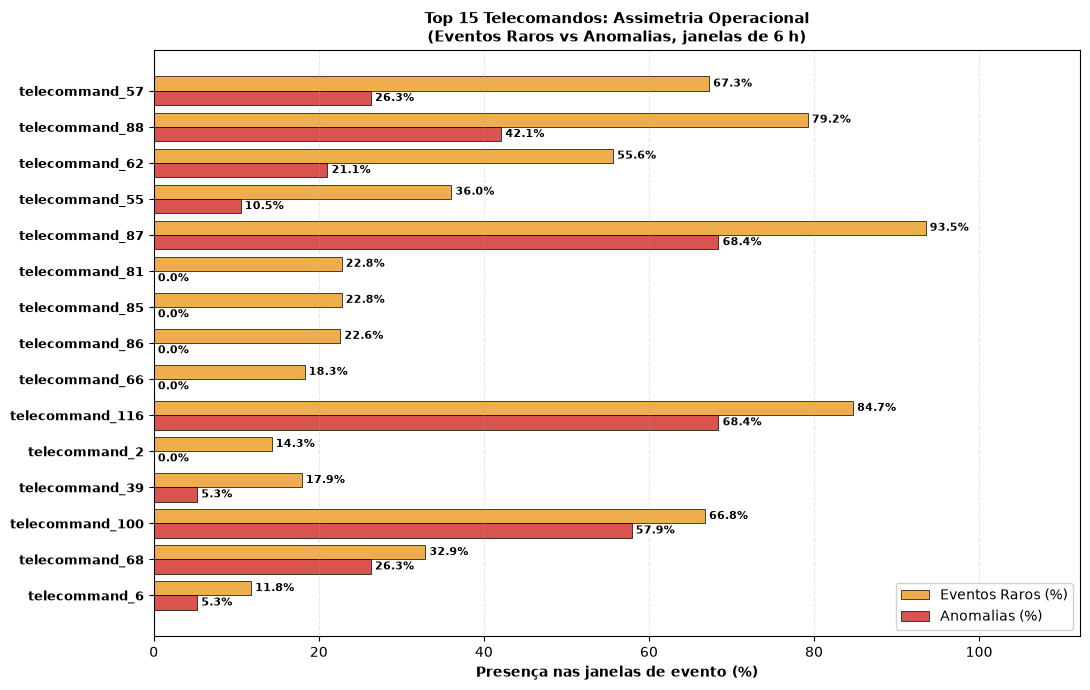

In [25]:
# 1. Métrica de destaque (diferença entre Raros e Anomalias), janelas de 6 h antes do evento
df_barras = (
    presenca_tc_por_tipo.loc[
        (presenca_tc_por_tipo["horas"] == 6) & (presenca_tc_por_tipo["tipo_janela"] == "evento")
    ]
    .pivot_table(index=["Telecommand", "Priority"], columns="Category",
                 values="pct_janelas_com_execucao")
    .reset_index()
    .fillna(0)
)
for cat in ["Anomaly", "Rare Event"]:
    if cat not in df_barras.columns:
        df_barras[cat] = 0

df_barras["diferenca_raro_anomalia"] = df_barras["Rare Event"] - df_barras["Anomaly"]
top_comandos = df_barras.sort_values("diferenca_raro_anomalia", ascending=False).head(15)
display(top_comandos.round(1))

fig, ax = plt.subplots(figsize=(11, 7))
y_pos = np.arange(len(top_comandos))
largura = 0.4
barras_raro = ax.barh(y_pos - largura / 2, top_comandos["Rare Event"], largura,
                      label="Eventos Raros (%)", color="#f0ad4e", edgecolor="black", linewidth=0.5)
barras_anomalia = ax.barh(y_pos + largura / 2, top_comandos["Anomaly"], largura,
                          label="Anomalias (%)", color="#d9534f", edgecolor="black", linewidth=0.5)
ax.bar_label(barras_raro, fmt="%.1f%%", padding=3, fontsize=8, fontweight="bold")
ax.bar_label(barras_anomalia, fmt="%.1f%%", padding=3, fontsize=8, fontweight="bold")
ax.set_yticks(y_pos)
ax.set_yticklabels(top_comandos["Telecommand"], fontsize=9, fontweight="bold")
ax.invert_yaxis()
ax.set_xlabel("Presença nas janelas de evento (%)", fontsize=10, fontweight="bold")
ax.set_title("Top 15 Telecomandos: Assimetria Operacional\n(Eventos Raros vs Anomalias, janelas de 6 h)",
             fontsize=11, fontweight="bold")
ax.set_xlim(0, max(float(top_comandos[["Rare Event", "Anomaly"]].max().max()) * 1.2, 10))
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.legend(loc="lower right", framealpha=0.9)
plt.tight_layout()
plt.show()

Telecomando de maior assimetria (Raro − Anomalia) em 6 h: telecommand_57


/tmp/ipykernel_117076/4121070628.py:41: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  return pickle.loads(z.read(nome_arquivo))


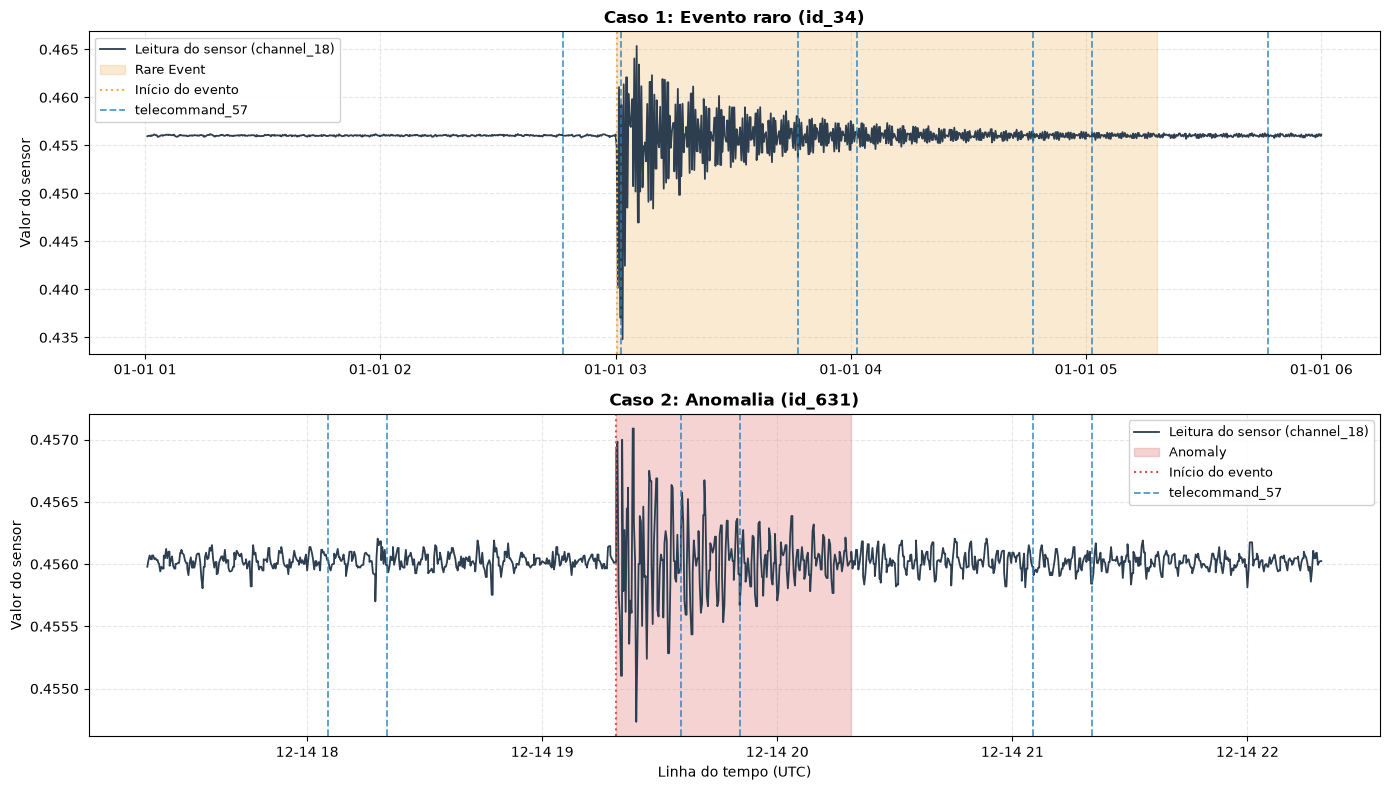


Resumo dos casos:

id_34 — Rare Event
Início: 2000-01-01 03:00:16.302000 | Fim máximo anotado: 2000-01-01 05:17:58.314000
Execuções de telecommand_57 nas 2h anteriores: 1
Último comando anterior: 2000-01-01 02:46:28.301000 | distância: 13.8 min

id_631 — Anomaly
Início: 2001-12-14 19:18:53.670000 | Fim máximo anotado: 2001-12-14 20:18:53.676000
Execuções de telecommand_57 nas 2h anteriores: 2
Último comando anterior: 2001-12-14 18:20:23.665000 | distância: 58.5 min


In [26]:
# ------------------------------------------------------------------------------
# Estudo de caso: o TC de maior assimetria, no canal de referência
# (na Mission1 foi o telecommand_38, com os eventos id_1 e id_18; aqui a escolha é automática)
# ------------------------------------------------------------------------------
tc_destaque = top_comandos["Telecommand"].iloc[0]
print(f"Telecomando de maior assimetria (Raro − Anomalia) em 6 h: {tc_destaque}")

serie_caso = pd.to_numeric(channels[CANAL_REF].iloc[:, 0], errors="coerce").dropna().sort_index()
tc_caso = load_zip_pickle(DATA_DIR / "telecommands" / f"{tc_destaque}.zip").sort_index()
if tc_caso.index.tz is not None:
    tc_caso.index = tc_caso.index.tz_convert("UTC").tz_localize(None)

eventos_33 = labels_rotuladas.loc[
    (labels_rotuladas["Channel"] == CANAL_REF)
    & labels_rotuladas["Category"].isin(["Anomaly", "Rare Event"]),
    ["ID", "Category", "StartTimeUTC", "EndTimeUTC"],
].copy()
eventos_33["inicio"] = para_naive(eventos_33["StartTimeUTC"])
eventos_33["fim"] = para_naive(eventos_33["EndTimeUTC"])


def n_tc_antes(inicio, horas=2):
    return len(tc_caso.loc[inicio - pd.Timedelta(hours=horas): inicio])


# Escolha automática: o primeiro evento de cada categoria que tem o TC nas 2 h anteriores;
# se não houver, o primeiro evento da categoria.
casos = []
for categoria, titulo in [("Rare Event", "Caso 1: Evento raro"), ("Anomaly", "Caso 2: Anomalia")]:
    candidatos = (
        eventos_33.loc[eventos_33["Category"] == categoria]
        .groupby("ID", as_index=False).agg(inicio=("inicio", "min"))
        .sort_values("inicio")
    )
    if candidatos.empty:
        print(f"⚠️ Nenhum evento de {categoria} no {CANAL_REF}.")
        continue
    com_tc = candidatos[[n_tc_antes(t) > 0 and t - pd.Timedelta(hours=2) >= serie_caso.index.min()
                         for t in candidatos["inicio"]]]
    escolhido = (com_tc if len(com_tc) else candidatos).iloc[0]
    casos.append((escolhido["ID"], categoria, titulo))

if casos:
    fig, axes = plt.subplots(len(casos), 1, figsize=(14, 4 * len(casos)), squeeze=False)
    for (evento_id, categoria, titulo), ax in zip(casos, axes[:, 0]):
        rotulos_evento = eventos_33.loc[(eventos_33["ID"] == evento_id) & (eventos_33["Category"] == categoria)]
        t_inicio = rotulos_evento["inicio"].min()
        janela_ini = t_inicio - pd.Timedelta(hours=2)
        janela_fim = t_inicio + pd.Timedelta(hours=3)
        telemetria = serie_caso.loc[janela_ini:janela_fim]
        comandos = tc_caso.loc[janela_ini:janela_fim]

        ax.plot(telemetria.index, telemetria.values, color="#2c3e50", linewidth=1.3,
                label=f"Leitura do sensor ({CANAL_REF})")
        for i, evento in enumerate(rotulos_evento.itertuples()):
            inicio_faixa = max(evento.inicio, janela_ini)
            fim_faixa = min(evento.fim, janela_fim)
            if inicio_faixa <= fim_faixa:
                ax.axvspan(inicio_faixa, fim_faixa, color=CORES_CATEGORIAS[categoria], alpha=0.25,
                           label=categoria if i == 0 else None)
        ax.axvline(t_inicio, color=CORES_CATEGORIAS[categoria], linestyle=":", linewidth=1.5,
                   label="Início do evento")
        for i, tc_time in enumerate(comandos.index):
            ax.axvline(tc_time, color="#2980b9", linestyle="--", linewidth=1.3, alpha=0.8,
                       label=tc_destaque if i == 0 else None)
        ax.set_title(f"{titulo} ({evento_id})", fontsize=12, fontweight="bold")
        ax.set_ylabel("Valor do sensor")
        ax.grid(True, linestyle="--", alpha=0.3)
        ax.legend(loc="best", fontsize=9, framealpha=0.9)
    axes[-1, 0].set_xlabel("Linha do tempo (UTC)")
    plt.tight_layout()
    plt.show()

    print("\nResumo dos casos:")
    for evento_id, categoria, _ in casos:
        evento = eventos_33.loc[(eventos_33["ID"] == evento_id) & (eventos_33["Category"] == categoria)]
        inicio, fim = evento["inicio"].min(), evento["fim"].max()
        comandos_antes = tc_caso.loc[inicio - pd.Timedelta(hours=2): inicio]
        print(f"\n{evento_id} — {categoria}")
        print(f"Início: {inicio} | Fim máximo anotado: {fim}")
        print(f"Execuções de {tc_destaque} nas 2h anteriores: {len(comandos_antes)}")
        if len(comandos_antes) > 0:
            ultimo = comandos_antes.index.max()
            print(f"Último comando anterior: {ultimo} | distância: {(inicio - ultimo).total_seconds() / 60:.1f} min")

**O que o gráfico mostra:** os 15 telecomandos com maior diferença de presença nas janelas de 6 h antes de **eventos raros** (laranja) e de **anomalias** (vermelho).

**Resultado.**

- **Maior assimetria:** `telecommand_57` (67,3% dos raros × 26,3% das anomalias), `telecommand_88` (79,2% × 42,1%), `telecommand_62` (55,6% × 21,1%) e `telecommand_55` (36,0% × 10,5%).
- **Ausentes antes de anomalias:** `telecommand_81`, `85`, `86`, `66` e `2` aparecem em 14–23% das janelas de eventos raros e em **0 de 19** anomalias.
- **Rotinas frequentes:** `telecommand_87` (93,5% × 68,4%), `telecommand_116` (84,7% × 68,4%) e `telecommand_100` (66,8% × 57,9%) aparecem em muitas janelas das duas classes: pouco informativos.
- **Estudo de caso (automático):** `telecommand_57`. No evento raro `id_34`, ele foi executado 13,8 min antes do início. Na anomalia `id_631`, ele **também** apareceu (duas execuções, a última 58,5 min antes). Este par ilustra, portanto, que o TC não é exclusivo de eventos raros.


**3.4 Como a distribuição dos códigos `Priority` dos telecomandos presentes em janelas de evento se compara à disponibilidade geral no catálogo?**

> A coluna `Priority` existe no catálogo e será usada como categoria, sem presumir que valores maiores ou menores indiquem criticidade. A comparação contará tipos de TC, não total bruto de execuções, e será descritiva.

Disponibilidade geral por código Priority:


,Priority,tipos_catalogo,tipos_com_execucao_no_periodo,pct_catalogo_com_execucao_no_periodo
0,2,119,119,100.0
1,3,4,4,100.0


Tipos de TC que apareceram em ao menos uma janela de 6 h:


,Category,tipo_janela,Priority,tipos_observados,tipos_com_execucao,tipos_catalogo,pct_tipos_com_execucao
0,Anomaly,evento,2,119,64,119,53.8
1,Anomaly,evento,3,4,3,4,75.0
2,Anomaly,referencia,2,119,61,119,51.3
3,Anomaly,referencia,3,4,0,4,0.0
4,Rare Event,evento,2,119,92,119,77.3
5,Rare Event,evento,3,4,4,4,100.0
6,Rare Event,referencia,2,119,80,119,67.2
7,Rare Event,referencia,3,4,2,4,50.0


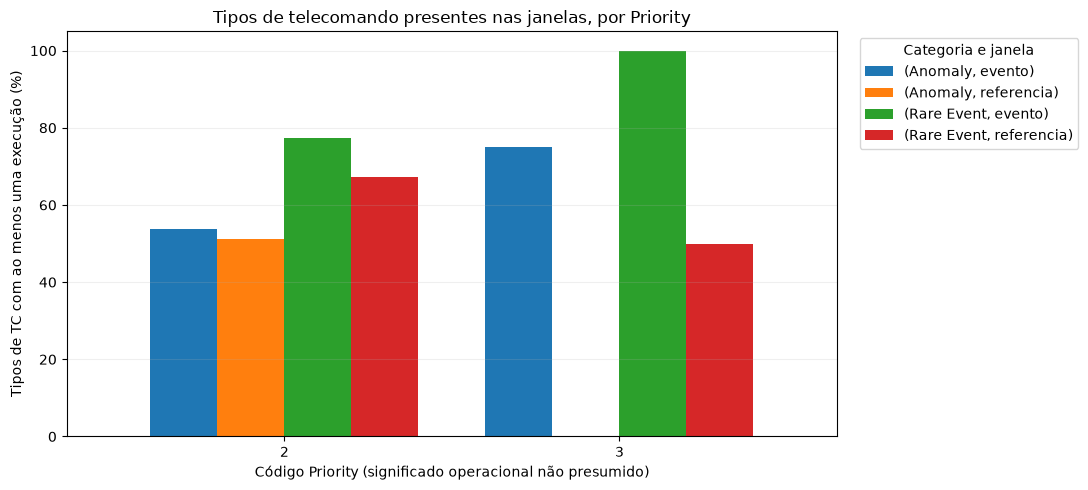

In [27]:
base_prioridade = (
    contagens_tc.groupby("Priority", dropna=False)
    .agg(
        tipos_catalogo=("Telecommand", "nunique"),
        tipos_com_execucao_no_periodo=("execucoes_no_periodo", lambda valores: int((valores > 0).sum())),
    )
    .reset_index()
)
base_prioridade["pct_catalogo_com_execucao_no_periodo"] = (
    100 * base_prioridade["tipos_com_execucao_no_periodo"] / base_prioridade["tipos_catalogo"]
)

presenca_6h = presenca_tc_por_tipo.loc[
    (presenca_tc_por_tipo["horas"] == 6)
    & presenca_tc_por_tipo["tipo_janela"].isin(["evento", "referencia"])
].copy()
presenca_6h["apareceu_em_ao_menos_uma_janela"] = presenca_6h["janelas_com_execucao"] > 0
resumo_prioridade_contexto = (
    presenca_6h.groupby(["Category", "tipo_janela", "Priority"], dropna=False)
    .agg(
        tipos_observados=("Telecommand", "nunique"),
        tipos_com_execucao=("apareceu_em_ao_menos_uma_janela", "sum"),
    )
    .reset_index()
    .merge(base_prioridade[["Priority", "tipos_catalogo"]], on="Priority", how="left")
)
resumo_prioridade_contexto["pct_tipos_com_execucao"] = (
    100 * resumo_prioridade_contexto["tipos_com_execucao"] / resumo_prioridade_contexto["tipos_catalogo"]
)

print("Disponibilidade geral por código Priority:")
display(base_prioridade.round(1))
print("Tipos de TC que apareceram em ao menos uma janela de 6 h:")
display(resumo_prioridade_contexto.round(1))

pivot_prioridade = resumo_prioridade_contexto.pivot_table(
    index="Priority", columns=["Category", "tipo_janela"], values="pct_tipos_com_execucao",
)
ax = pivot_prioridade.plot(kind="bar", figsize=(11, 5), width=0.8)
ax.set_xlabel("Código Priority (significado operacional não presumido)")
ax.set_ylabel("Tipos de TC com ao menos uma execução (%)")
ax.set_title("Tipos de telecomando presentes nas janelas, por Priority")
ax.grid(axis="y", alpha=0.2)
ax.legend(title="Categoria e janela", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Resultado.** Há só **dois códigos** `Priority`: **2 (119 tipos)** e **3 (4 tipos)**. Todos os tipos aparecem no período.

| Priority | Anomalia: evento / ref. | Raro: evento / ref. |
|---|---|---|
| 2 (119 tipos) | 53,8% / 51,3% | 77,3% / 67,2% |
| 3 (4 tipos) | 75,0% (3 de 4) / 0% | 100% (4 de 4) / 50% (2 de 4) |

- **Priority 2:** antes de anomalias, a diversidade de TCs é igual à da referência (53,8% × 51,3%). Antes de eventos raros ela é maior (77,3% × 67,2%), o que sugere mais atividade operacional nessas janelas.
- **Priority 3:** só 4 tipos, então os percentuais saltam de 25 em 25 pontos. Eles aparecem mais nas janelas de evento do que nas de referência (3 de 4 × 0 de 4 antes de anomalias; 4 de 4 × 2 de 4 antes de raros), mas com amostra tão pequena isso é apenas uma pista.

#### 4. Qualidade dos Dados

**4.1 Qual é a regularidade temporal dos registros e quantas leituras nulas, não numéricas ou infinitas existem em cada canal?**

> Timestamp repetido, valor nulo e pausa entre leituras são situações diferentes. Zero é uma leitura registrada, não um valor inválido por definição. Sem uma grade de coleta esperada e documentada, não estimaremos "percentual do tempo com dados válidos".

In [28]:
linhas_qualidade = []
for nome, df in channels.items():
    valores = pd.to_numeric(df.iloc[:, 0], errors="coerce").to_numpy(dtype=float)
    intervalos_s = intervalos_em_segundos(df.index)
    mediana_canal = float(np.median(intervalos_s[intervalos_s > 0]))
    linhas_qualidade.append({
        "canal": nome,
        "leituras": len(df),
        "valores_nulos_ou_nao_numericos": int(np.isnan(valores).sum()),
        "valores_infinitos": int(np.isinf(valores).sum()),
        "fracao_zeros_pct": 100 * float(np.nanmean(valores == 0)),
        "valores_distintos": int(pd.Series(valores).nunique()),
        "intervalos_acima_5min": int((intervalos_s > 300).sum()),
        "intervalos_acima_1h": int((intervalos_s > 3600).sum()),
        "intervalos_>10x_mediana": int((intervalos_s > 10 * mediana_canal).sum()),
        "maior_intervalo_min": float(np.max(intervalos_s) / 60),
    })
qualidade_canais = pd.DataFrame(linhas_qualidade).set_index("canal")
display(qualidade_canais.round(2))
print(
    "As pausas são contagens sob limites declarados; não equivalem a valores ausentes "
    "nem confirmam falha de aquisição. Canais com poucos valores distintos podem ser "
    "flags/contadores e não sinais contínuos."
)

,leituras,valores_nulos_ou_nao_numericos,valores_infinitos,fracao_zeros_pct,valores_distintos,intervalos_acima_5min,intervalos_acima_1h,intervalos_>10x_mediana,maior_intervalo_min
canal,,,,,,,,,
channel_18,7387262,0,0,0.0,90474,1,0,1,37.8
channel_19,7387262,0,0,0.0,59423,1,0,1,37.8
channel_20,7387262,0,0,0.0,82195,1,0,1,37.8
channel_21,7387262,0,0,0.0,55482,1,0,1,37.8
channel_22,7387262,0,0,0.0,62657,1,0,1,37.8
channel_23,7387262,0,0,0.0,76065,1,0,1,37.8
channel_24,7387262,0,0,0.0,83366,1,0,1,37.8
channel_25,7387262,0,0,0.0,385345,1,0,1,37.8
channel_26,7387262,0,0,0.0,177477,1,0,1,37.8


As pausas são contagens sob limites declarados; não equivalem a valores ausentes nem confirmam falha de aquisição. Canais com poucos valores distintos podem ser flags/contadores e não sinais contínuos.


**Resultado.**

- **Valores nulos, não numéricos ou infinitos:** zero em todos os 11 canais.
- **Zeros:** fração de 0,0% em todos os canais (o mínimo 0 do `channel_18` é raro). Não há zeros em sequência como na Mission1.
- **Valores distintos:** de ~55 mil (`channel_21`) a ~385 mil (`channel_25`). São sinais contínuos, sem canais tipo flag/contador no recorte.
- **Pausas:** cada canal tem **1** intervalo acima de 5 min (e acima de 10× a mediana), de 37,8 min, e nenhum acima de 1 h; os valores são idênticos entre canais porque os timestamps coincidem.

Em resumo, a qualidade é boa: nenhuma lacuna longa e nenhum valor inválido. Pausas não equivalem a valores ausentes.

**4.2 As janelas de uma hora a partir do início anotado apresentam mais pausas ou sequências constantes que referências sem rótulos, também com uma hora?**

> A comparação usa a mesma duração para evento e referência. "Sem rótulo" é apenas ausência de anotação conhecida, não normalidade confirmada. Sequência constante descreve leituras repetidas, não prova travamento do sensor. Como limiar de pausa usamos **2 × o intervalo mediano** (na Mission1, 60 s = 2 × 30 s). Cada janela de referência tem 1 h, termina antes do evento e não cruza nenhum rótulo do canal.

In [29]:
duracao_janela = pd.Timedelta(hours=1)
LIMIAR_PAUSA_42_S = 2 * MEDIANA_AMOSTRAGEM_S
MIN_CONST_MIN = 10   # minutos de leituras idênticas para contar como "sequência constante"

serie_42 = pd.to_numeric(channels[CANAL_REF].iloc[:, 0], errors="coerce").dropna().sort_index()
rot_42 = labels_rotuladas.loc[labels_rotuladas["Channel"] == CANAL_REF].copy()
rot_42["inicio"] = para_naive(rot_42["StartTimeUTC"])
rot_42["fim"] = para_naive(rot_42["EndTimeUTC"])
ini_42 = rot_42["inicio"].to_numpy()
fim_42 = rot_42["fim"].to_numpy()


def analisar_janela(ini, fim):
    """Retorna (teve_pausa, teve_sequencia_constante, n_leituras) ou None se vazia."""
    trecho = serie_42.loc[ini:fim]
    if len(trecho) < 2:
        return None
    difs = intervalos_em_segundos(trecho.index)
    teve_pausa = bool((difs > LIMIAR_PAUSA_42_S).any())
    seq = sequencias_constantes(trecho, 10 * MEDIANA_AMOSTRAGEM_S, min_leituras=2, min_duracao_min=MIN_CONST_MIN)
    return teve_pausa, len(seq) > 0, len(trecho)


linhas_42 = []
for _, ev in rot_42.loc[rot_42["Category"].isin(["Anomaly", "Rare Event", "Communication Gap"])].iterrows():
    r = analisar_janela(ev["inicio"], ev["inicio"] + duracao_janela)
    if r is not None:
        linhas_42.append({"grupo": ev["Category"], "teve_pausa": r[0], "teve_const": r[1], "n": r[2]})

    # Referência: 1 h, 1 a 8 semanas antes, sem cruzar nenhum rótulo do canal
    if ev["Category"] in ("Anomaly", "Rare Event"):
        for semanas in range(1, 9):
            ini_ref = ev["inicio"] - pd.Timedelta(weeks=semanas)
            fim_ref = ini_ref + duracao_janela
            cruza = bool(((ini_42 <= np.datetime64(fim_ref)) & (fim_42 >= np.datetime64(ini_ref))).any())
            if not cruza and ini_ref >= serie_42.index.min():
                rr = analisar_janela(ini_ref, fim_ref)
                if rr is not None:
                    linhas_42.append({"grupo": "Referência sem rótulo", "teve_pausa": rr[0],
                                      "teve_const": rr[1], "n": rr[2]})
                break

df_42 = pd.DataFrame(linhas_42)
resumo_42 = df_42.groupby("grupo").agg(
    janelas=("teve_pausa", "size"),
    com_pausa=("teve_pausa", "sum"),
    com_sequencia_constante=("teve_const", "sum"),
)
resumo_42["% com pausa"] = (100 * resumo_42["com_pausa"] / resumo_42["janelas"]).round(1)
resumo_42["% com sequência constante"] = (100 * resumo_42["com_sequencia_constante"] / resumo_42["janelas"]).round(1)
print(f"--- Primeira hora dos eventos × referências (pausa > {LIMIAR_PAUSA_42_S:g} s; "
      f"constante ≥ {MIN_CONST_MIN} min) — {CANAL_REF} ---")
display(resumo_42)

--- Primeira hora dos eventos × referências (pausa > 36 s; constante ≥ 10 min) — channel_18 ---


,janelas,com_pausa,com_sequencia_constante,% com pausa,% com sequência constante
grupo,,,,,
Anomaly,11,0,0,0.0,0.0
Rare Event,610,0,1,0.0,0.2
Referência sem rótulo,616,0,0,0.0,0.0


**Resultado.** Nenhuma das 1.237 janelas de 1 h teve pausa acima de 36 s (2× a mediana): 0 de 11 (anomalias), 0 de 610 (raros) e 0 de 616 (referências). Só **uma** janela de evento raro teve sequência constante de ≥ 10 min (0,2%); anomalias e referências tiveram nenhuma.

**4.3 Como os valores extremos do canal de referência, definidos no período inicial, se distribuem no período posterior entre janelas anotadas e períodos sem anotação conhecida?**

> Os percentis serão estimados só na primeira metade e aplicados à segunda. "Sem rótulo conhecido" não significa ausência comprovada de anomalia. Os limites são descritivos, não limiares físicos nem um detector validado.

Limites P1 e P99 estimados no período inicial: 0.4558 e 0.4563
Total de leituras fora dos limites no período posterior: 107,540


,Leituras Extremas,Percentual (%)
Anomaly,86,0.08
Rare Event,80446,74.81
Communication Gap,0,0.00
Mais de uma categoria,0,0.00
Sem anotação conhecida,27008,25.11


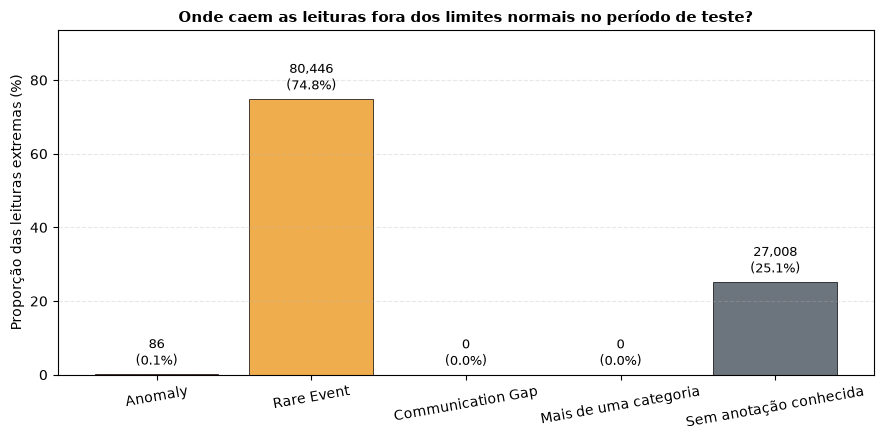

In [30]:
canal_extremos = CANAL_REF
serie_extremos = pd.to_numeric(channels[canal_extremos].iloc[:, 0], errors="coerce")
indice_extremos = serie_extremos.index

# Dividimos o histórico em duas metades: referência (treino) e teste
corte_extremos = indice_extremos.min() + (indice_extremos.max() - indice_extremos.min()) / 2
referencia_extremos = serie_extremos.loc[indice_extremos < corte_extremos]
teste_extremos = serie_extremos.loc[indice_extremos >= corte_extremos]

# Percentis de referência (1% inferior e 1% superior)
p01, p99 = referencia_extremos.quantile([0.01, 0.99])
mascara_extremos = (teste_extremos < p01) | (teste_extremos > p99)

timestamps_extremos_ns = indice_ns(teste_extremos.index[mascara_extremos.to_numpy()])

print(f"Limites P1 e P99 estimados no período inicial: {p01:.4f} e {p99:.4f}")
print(f"Total de leituras fora dos limites no período posterior: {len(timestamps_extremos_ns):,}")

rotulos_extremos = labels_rotuladas.loc[
    (labels_rotuladas["Channel"] == canal_extremos)
    & labels_rotuladas["Category"].isin(["Anomaly", "Rare Event", "Communication Gap"]),
    ["Category", "StartTimeUTC", "EndTimeUTC"],
].copy()
rotulos_extremos["inicio"] = para_naive(rotulos_extremos["StartTimeUTC"])
rotulos_extremos["fim"] = para_naive(rotulos_extremos["EndTimeUTC"])


def unir_intervalos_ns(grupo_rotulos: pd.DataFrame):
    """Une intervalos sobrepostos em NANOSSEGUNDOS (int64), independente da resolução do pandas."""
    if grupo_rotulos.empty:
        return np.array([], dtype=np.int64), np.array([], dtype=np.int64)

    inicios = grupo_rotulos["inicio"].astype("datetime64[ns]").astype("int64").to_numpy()
    fins = grupo_rotulos["fim"].astype("datetime64[ns]").astype("int64").to_numpy()

    pares = sorted(zip(inicios, fins))
    unidos = []
    for ini, fim in pares:
        if unidos and ini <= unidos[-1][1]:
            unidos[-1] = (unidos[-1][0], max(unidos[-1][1], fim))
        else:
            unidos.append((ini, fim))
    return (np.array([p[0] for p in unidos], dtype=np.int64),
            np.array([p[1] for p in unidos], dtype=np.int64))


def dentro_de_intervalos(timestamps_ns: np.ndarray, inicios_ns: np.ndarray, fins_ns: np.ndarray) -> np.ndarray:
    """Verifica com busca binária quais timestamps caem dentro dos intervalos anotados."""
    if len(inicios_ns) == 0:
        return np.zeros(len(timestamps_ns), dtype=bool)
    posicoes = np.searchsorted(inicios_ns, timestamps_ns, side="right") - 1
    validas = posicoes >= 0
    resultado = np.zeros(len(timestamps_ns), dtype=bool)
    resultado[validas] = timestamps_ns[validas] <= fins_ns[posicoes[validas]]
    return resultado


categorias_rotulo = ["Anomaly", "Rare Event", "Communication Gap"]
mascaras_por_categoria = {}
for cat in categorias_rotulo:
    grupo = rotulos_extremos.loc[rotulos_extremos["Category"] == cat]
    inicios_ns, fins_ns = unir_intervalos_ns(grupo)
    mascaras_por_categoria[cat] = dentro_de_intervalos(timestamps_extremos_ns, inicios_ns, fins_ns)

# Classificação de cada leitura extrema (vetorizada)
matriz_masc = np.column_stack([mascaras_por_categoria[c] for c in categorias_rotulo]) \
    if len(timestamps_extremos_ns) else np.zeros((0, len(categorias_rotulo)), dtype=bool)
n_coincidentes = matriz_masc.sum(axis=1)
classificacao_extremos = np.where(
    n_coincidentes == 0, "Sem anotação conhecida",
    np.where(n_coincidentes > 1, "Mais de uma categoria",
             np.array(categorias_rotulo)[matriz_masc.argmax(axis=1)] if len(matriz_masc) else "")
)

ordem_contextos = ["Anomaly", "Rare Event", "Communication Gap", "Mais de uma categoria", "Sem anotação conhecida"]
contagem_extremos = pd.Series(classificacao_extremos).value_counts().reindex(ordem_contextos, fill_value=0)
percentuais_extremos = (contagem_extremos / max(len(classificacao_extremos), 1)) * 100

tabela_extremos = pd.DataFrame({
    "Leituras Extremas": contagem_extremos,
    "Percentual (%)": percentuais_extremos.round(2),
})
display(tabela_extremos)

fig, ax = plt.subplots(figsize=(9, 4.5))
cores_grafico = [CORES_CATEGORIAS.get(c, "#6c757d") for c in tabela_extremos.index]
barras = ax.bar(tabela_extremos.index, tabela_extremos["Percentual (%)"],
                color=cores_grafico, edgecolor="black", linewidth=0.5)
ax.bar_label(
    barras,
    labels=[f"{n:,}\n({pct:.1f}%)" for n, pct in zip(tabela_extremos["Leituras Extremas"],
                                                      tabela_extremos["Percentual (%)"])],
    padding=4, fontsize=9,
)
ax.set_ylim(0, max(1, float(tabela_extremos["Percentual (%)"].max()) * 1.25))
ax.set_ylabel("Proporção das leituras extremas (%)", fontsize=10)
ax.set_title("Onde caem as leituras fora dos limites normais no período de teste?",
             fontsize=11, fontweight="bold")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.tick_params(axis="x", rotation=10)
plt.tight_layout()
plt.show()

**Resultado.** Os limites P1 e P99, estimados na primeira metade, são 0,4558 e 0,4563, uma faixa de apenas 0,0005. No período posterior, **107.540 leituras** ficam fora dela:

| Onde caem | Leituras | % |
|---|---|---|
| Janela de evento raro | 80.446 | 74,8% |
| Sem anotação conhecida | 27.008 | 25,1% |
| Janela de anomalia | 86 | 0,08% |

- Quase três quartos das leituras extremas caem em janelas de **eventos raros**. Na Mission1, eventos raros e anomalias se distribuíam mais igualmente.
- Os 25,1% **sem anotação** podem ser variações legítimas não rotuladas, rótulos incompletos ou apenas ruído numa faixa tão estreita. Ausência de rótulo não é prova de normalidade.
- Só 86 leituras caem em anomalia, porque o período de teste tem **uma** anomalia (ver 1.4).

**Cuidado:** o percentual de 74,8% não foi comparado com a fração do tempo coberta por rótulos de eventos raros. Seria preciso saber essa fração para dizer se as leituras extremas se concentram nesses intervalos ou se eles só cobrem muito tempo. Os limites são descritivos, não um detector validado.

#### 5. Detecção de Anomalias com Limites

**5.1 Se ajustarmos uma regra robusta no período inicial e a aplicarmos no período posterior, quantas leituras serão sinalizadas, quantos episódios isso forma e com quais categorias anotadas coincidem?**

In [31]:
canal_detector = CANAL_REF
serie_detector = pd.to_numeric(channels[canal_detector].iloc[:, 0], errors="coerce").dropna().sort_index()

# Divisão temporal (50% treino / 50% teste)
corte_detector = serie_detector.index.min() + (serie_detector.index.max() - serie_detector.index.min()) / 2
serie_treino = serie_detector.loc[serie_detector.index < corte_detector]
serie_teste = serie_detector.loc[serie_detector.index >= corte_detector]

# 1. Rótulos do canal
rotulos_canal = labels_rotuladas.loc[labels_rotuladas["Channel"] == canal_detector].copy()
rotulos_canal["inicio"] = para_naive(rotulos_canal["StartTimeUTC"])
rotulos_canal["fim"] = para_naive(rotulos_canal["EndTimeUTC"])

# 2. CALIBRAÇÃO NÃO CONTAMINADA: pontos do treino que NÃO são zero e NÃO caem em eventos rotulados
inicios_treino_ns, fins_treino_ns = unir_intervalos_ns(rotulos_canal[rotulos_canal["inicio"] < corte_detector])
mascara_em_evento_treino = dentro_de_intervalos(indice_ns(serie_treino.index), inicios_treino_ns, fins_treino_ns)
treino_limpo = serie_treino.loc[(serie_treino > 0) & (~mascara_em_evento_treino)]
if len(treino_limpo) < 100:   # canal em que o zero é um valor legítimo
    treino_limpo = serie_treino.loc[~mascara_em_evento_treino]

mediana_treino, escala_mad = estimar_nominal(treino_limpo, excluir_zeros=False)

print("--- Calibração Limpa (sem eventos rotulados; zeros excluídos quando possível) ---")
print(f"Mediana nominal: {mediana_treino:.4f}")
print(f"Escala robusta (MAD*1,4826): {escala_mad:.5f}\n")

# 3. Aplicação no período de teste (zeros como categoria própria: possível perda de telemetria)
score_teste = (serie_teste - mediana_treino).abs() / escala_mad
alerta_limite = (score_teste > 3) & (serie_teste > 0)
alerta_zero = serie_teste == 0
alerta_total = alerta_limite | alerta_zero

print(f"Total de leituras no teste: {len(serie_teste):,}")
print(f"Leituras com desvio > 3 MAD: {int(alerta_limite.sum()):,} ({100*alerta_limite.mean():.2f}%)")
print(f"Leituras com valor zero: {int(alerta_zero.sum()):,}")

# 4. AGRUPAMENTO EM EPISÓDIOS (tolerância temporal de 30 minutos)
timestamps_alertas = serie_teste.index[alerta_total.to_numpy()]
episodios = []
if len(timestamps_alertas) > 0:
    janela_tolerancia = pd.Timedelta(minutes=30)
    inicio_ep = fim_ep = timestamps_alertas[0]
    pontos_ep = 1
    for ts in timestamps_alertas[1:]:
        if ts - fim_ep <= janela_tolerancia:
            fim_ep = ts
            pontos_ep += 1
        else:
            episodios.append({"inicio": inicio_ep, "fim": fim_ep, "leituras": pontos_ep})
            inicio_ep = fim_ep = ts
            pontos_ep = 1
    episodios.append({"inicio": inicio_ep, "fim": fim_ep, "leituras": pontos_ep})

df_episodios = pd.DataFrame(episodios, columns=["inicio", "fim", "leituras"])

# 5. Cruzamento dos episódios com os rótulos reais
rotulos_teste = rotulos_canal.loc[rotulos_canal["fim"] >= corte_detector].copy()


def classificar_episodio(row):
    intersecoes = rotulos_teste.loc[(rotulos_teste["inicio"] <= row["fim"]) & (rotulos_teste["fim"] >= row["inicio"])]
    cats = intersecoes["Category"].dropna().unique()
    if len(cats) == 0:
        return "Sem anotação conhecida"
    elif len(cats) == 1:
        return cats[0]
    return "Múltiplas categorias"


if len(df_episodios):
    df_episodios["categoria"] = df_episodios.apply(classificar_episodio, axis=1)
else:
    df_episodios["categoria"] = []

print("\n--- Resumo dos Episódios de Alerta (unidos por janela de 30 min) ---")
print(f"Total de episódios consolidados: {len(df_episodios)}")
display(df_episodios["categoria"].value_counts().to_frame("Total de Episódios"))

# 6. Avaliação por evento: quantos eventos rotulados dispararam pelo menos 1 alerta?
print("\n--- Sensibilidade por Evento Rotulado (Período de Teste) ---")
resumo_sensibilidade = []
for cat in ["Anomaly", "Rare Event"]:
    eventos_cat = rotulos_teste.loc[rotulos_teste["Category"] == cat]
    total_ev = len(eventos_cat)
    detectados = sum(
        1 for _, ev in eventos_cat.iterrows() if alerta_total.loc[ev["inicio"]: ev["fim"]].any()
    )
    pct = (detectados / total_ev * 100) if total_ev > 0 else 0
    resumo_sensibilidade.append({
        "Categoria": cat, "Eventos no Teste": total_ev,
        "Detectados (>= 1 alerta)": detectados, "Taxa de Detecção (%)": round(pct, 1),
    })
display(pd.DataFrame(resumo_sensibilidade).set_index("Categoria"))

# 7. Pontuação máxima por evento rotulado (período de teste): alimenta a 5.2
linhas_scores_eventos = []
for _, ev in rotulos_teste.iterrows():
    cat = ev["Category"]
    if cat not in ("Anomaly", "Rare Event"):
        continue
    trecho = score_teste.loc[ev["inicio"]: ev["fim"]]
    if len(trecho) == 0:
        continue
    linhas_scores_eventos.append({"ID": ev["ID"], "Category": cat, "score_maximo": float(trecho.max())})
df_scores_eventos = pd.DataFrame(linhas_scores_eventos, columns=["ID", "Category", "score_maximo"])

print("\n--- Escore máximo por evento rotulado (período de teste) ---")
display(df_scores_eventos.groupby("Category")["score_maximo"].agg(n="count", mediana="median", maximo="max").round(2))

--- Calibração Limpa (sem eventos rotulados; zeros excluídos quando possível) ---
Mediana nominal: 0.4560
Escala robusta (MAD*1,4826): 0.00005

Total de leituras no teste: 3,678,390
Leituras com desvio > 3 MAD: 151,688 (4.12%)
Leituras com valor zero: 0

--- Resumo dos Episódios de Alerta (unidos por janela de 30 min) ---
Total de episódios consolidados: 8459


,Total de Episódios
categoria,
Sem anotação conhecida,8122
Rare Event,336
Anomaly,1



--- Sensibilidade por Evento Rotulado (Período de Teste) ---


,Eventos no Teste,Detectados (>= 1 alerta),Taxa de Detecção (%)
Categoria,,,
Anomaly,1,1,100.0
Rare Event,344,344,100.0



--- Escore máximo por evento rotulado (período de teste) ---


,n,mediana,maximo
Category,,,
Anomaly,1,23.51,23.51
Rare Event,344,228.58,9904.54


**Resultado.** A regra (mediana 0,4560; escala robusta 0,00005; alerta se desvio > 3 MAD) sinaliza **151.688 de 3.678.390 leituras (4,12%)** no teste. Não há leituras iguais a zero.

- **Episódios:** 8.459 (leituras próximas unidas por 30 min). **8.122 (96,0%) não têm nenhuma anotação**, 336 coincidem com evento raro e **1** com anomalia.
- **Sensibilidade:** detectou 344 de 344 eventos raros e 1 de 1 anomalia. Os escores máximos são de 228,6 (mediana dos raros, máximo 9.904,5) e 23,5 (anomalia).

1. A regra praticamente **sempre dispara**, mas a taxa de 100% não é mérito: com uma escala de 0,00005 (≈ 0,01% da mediana), qualquer variação a ultrapassa. O resultado mais informativo é o oposto: **96% dos episódios de alerta não coincidem com evento anotado**, e há ~8,5 mil episódios para 345 eventos anotados no teste.
2. A taxa de detecção de anomalias vale para **uma** anomalia e não permite concluir nada sobre anomalias em geral.
3. Esta é uma **baseline exploratória**, sem avaliação formal. Episódios "sem anotação conhecida" não são necessariamente falsos positivos, pois os rótulos podem ser incompletos.

Isso ilustra o problema central da pesquisa: um alerta isolado não diz se é falha, operação ou ruído.

**5.2 Os scores da regra robusta diferem entre intervalos de teste anotados como `Anomaly` e `Rare Event` no canal de referência?**

> Vamos resumir o score máximo por intervalo, usando apenas a parte dos intervalos dentro do período posterior. Eventos pontuais sem uma amostra exatamente no timestamp serão contados como sem score disponível; não vamos deslocar o rótulo para favorecer o detector.

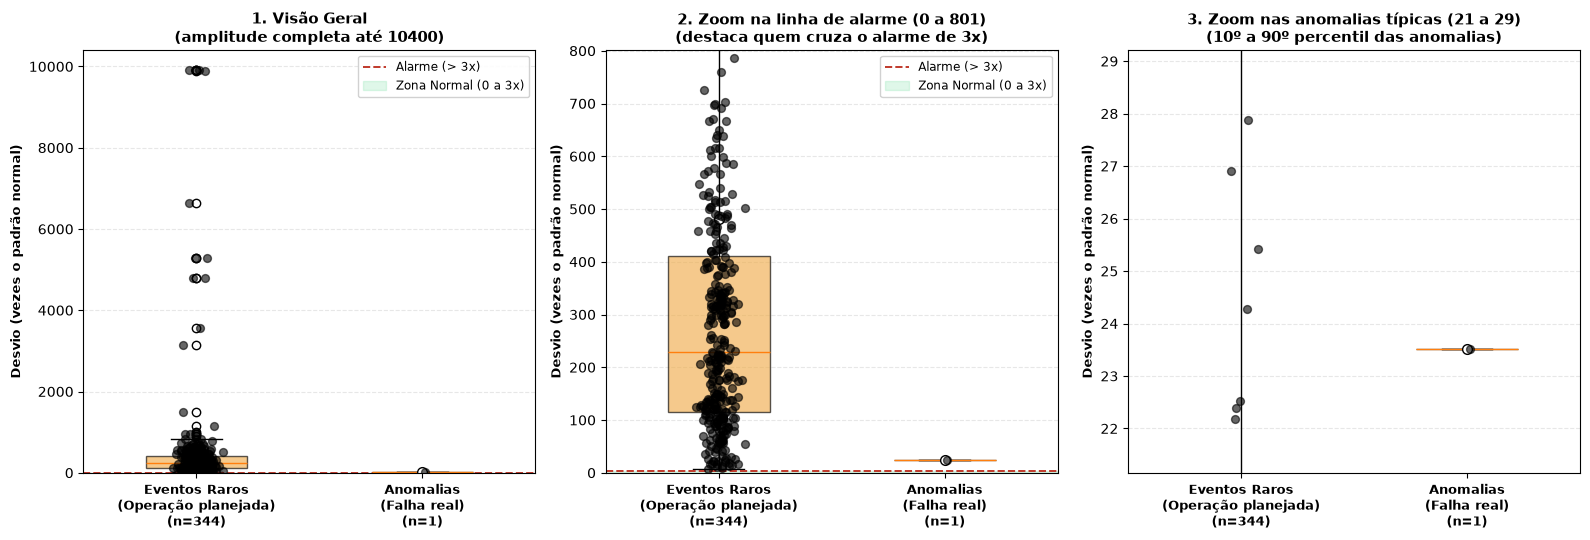

,n,mediana,% acima de 3x
Categoria,,,
Rare Event,344,228.58,100.0
Anomaly,1,23.51,100.0


In [32]:
categorias_plot = ["Rare Event", "Anomaly"]
rotulos_legiveis = ["Eventos Raros\n(Operação planejada)", "Anomalias\n(Falha real)"]
cores_box = [CORES_CATEGORIAS["Rare Event"], CORES_CATEGORIAS["Anomaly"]]

dados_plot = [
    df_scores_eventos.loc[df_scores_eventos["Category"] == cat, "score_maximo"].dropna()
    for cat in categorias_plot
]
todos_scores = pd.concat(dados_plot)
if todos_scores.empty:
    print("Sem scores disponíveis no período de teste para este canal.")
else:
    # Faixas de zoom calculadas a partir dos próprios dados (Mission1: 0–125, 0–10 e 15–28)
    topo_total = float(todos_scores.max()) * 1.05
    topo_zoom_raros = max(float(dados_plot[0].quantile(0.9)) * 1.3, 6.0) if len(dados_plot[0]) else 10.0
    if len(dados_plot[1]):
        q10_an, q90_an = float(dados_plot[1].quantile(0.1)), float(dados_plot[1].quantile(0.9))
        faixa_anom = (max(q10_an * 0.9, 0), max(q90_an * 1.1, q10_an * 1.2 + 1))
    else:
        faixa_anom = (0, topo_total)

    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 5.5))

    def desenhar_painel(ax, titulo, subtitulo, limite_y, mostrar_alarme=True):
        bp = ax.boxplot(
            dados_plot, patch_artist=True, widths=0.45, showmeans=True,
            meanprops={"marker": "o", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": 7},
        )
        ax.set_xticks([1, 2])
        ax.set_xticklabels([f"{r}\n(n={len(d)})" for r, d in zip(rotulos_legiveis, dados_plot)],
                           fontsize=9.5, fontweight="bold")
        for patch, cor in zip(bp["boxes"], cores_box):
            patch.set_facecolor(cor)
            patch.set_alpha(0.65)
        for i, valores in enumerate(dados_plot):
            rng = np.random.default_rng(42)
            x = rng.normal(i + 1, 0.04, size=len(valores))
            ax.scatter(x, valores, color="black", alpha=0.6, s=32, zorder=3)
        if mostrar_alarme:
            ax.axhline(3, color="#c0392b", linestyle="--", linewidth=1.4, label="Alarme (> 3x)")
            ax.axhspan(0, 3, color="#2ecc71", alpha=0.15, label="Zona Normal (0 a 3x)")
            ax.legend(loc="upper right", framealpha=0.9, fontsize=8.5)
        ax.set_ylabel("Desvio (vezes o padrão normal)", fontsize=9.5, fontweight="bold")
        ax.set_title(f"{titulo}\n{subtitulo}", fontsize=10.5, fontweight="bold")
        ax.set_ylim(limite_y)
        ax.grid(axis="y", linestyle="--", alpha=0.3)

    desenhar_painel(ax1, "1. Visão Geral", f"(amplitude completa até {topo_total:.0f})", (0, topo_total))
    desenhar_painel(ax2, f"2. Zoom na linha de alarme (0 a {topo_zoom_raros:.0f})",
                    "(destaca quem cruza o alarme de 3x)", (0, topo_zoom_raros))
    desenhar_painel(ax3, f"3. Zoom nas anomalias típicas ({faixa_anom[0]:.0f} a {faixa_anom[1]:.0f})",
                    "(10º a 90º percentil das anomalias)", faixa_anom, mostrar_alarme=False)
    plt.tight_layout()
    plt.show()

    resumo_scores = pd.DataFrame({
        "Categoria": categorias_plot,
        "n": [len(d) for d in dados_plot],
        "mediana": [d.median() for d in dados_plot],
        "% acima de 3x": [100 * (d > 3).mean() if len(d) else np.nan for d in dados_plot],
    }).set_index("Categoria").round(2)
    display(resumo_scores)

**Resultado.** Há **uma** anomalia no teste (escore máximo 23,5x) contra **344** intervalos de evento raro (mediana 228,6x, 100% acima de 3x). Com n = 1, **não é possível comparar** as duas distribuições nesta divisão; o gráfico de caixas das anomalias é um único ponto. O que se vê é que os eventos raros apresentam escores muito altos, mas sem uma amostra de anomalias não dá para dizer que há sobreposição, nem que não há.